# EXPLORATORY DATA ANALYSIS LAB — BCSE331P
**Name:** Revanth

**Reg.No:** 23BDS0027

**Dataset:** Fishing.csv


## SETUP

In [1]:
import math, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 115)
data_path = "fishing.csv"

def scale(df):
    return (df - df.mean()) / df.std(ddof=1)

def get_mode(s):
    return s.dropna().value_counts().idxmax()

def skewness(x):
    x = np.asarray(pd.Series(x).dropna(), dtype=float); n = len(x)
    m2 = np.mean((x - x.mean())**2); m3 = np.mean((x - x.mean())**3)
    return (m3 / m2**1.5) * ((n - 1) / n)**1.5

def kurtosis(x):
    x = np.asarray(pd.Series(x).dropna(), dtype=float); n = len(x)
    m2 = np.mean((x - x.mean())**2); m4 = np.mean((x - x.mean())**4)
    return (m4 / m2**2) * ((n - 1) / n)**2 - 3
print("Using dataset:", data_path)

Using dataset: fishing.csv


## ASSESSMENT I — Merging and Data Transformation

### Part 1: Merging / Concatenating data frames

**Create three data frames from the Fishing data.**

In [2]:
raw = pd.read_csv(data_path)
dataframe1 = raw.loc[0:9, ["rownames", "mode", "price"]].copy()
dataframe2 = raw.loc[5:14, ["rownames", "income"]].copy()
dataframe3 = raw.loc[200:209, ["rownames", "mode", "price"]].copy()
print("--- dataframe1 ---"); print(dataframe1)
print("\n--- dataframe2 ---"); print(dataframe2)
print("\n--- dataframe3 ---"); print(dataframe3)

--- dataframe1 ---
   rownames     mode    price
0         1  charter  182.930
1         2  charter   34.534
2         3     boat   24.334
3         4     pier   15.134
4         5     boat   41.514
5         6  charter   63.934
6         7    beach   51.934
7         8  charter   56.714
8         9     boat   34.914
9        10     boat   28.314

--- dataframe2 ---
    rownames     income
5          6  4583.3320
6          7  8750.0010
7          8  2083.3332
8          9  3749.9999
9         10  2916.6666
10        11  3749.9999
11        12  7083.3317
12        13  1249.9998
13        14  2083.3332
14        15  8750.0010

--- dataframe3 ---
     rownames     mode    price
200       201     boat  101.898
201       202    beach  117.306
202       203  charter  163.706
203       204     pier   26.106
204       205  charter   72.506
205       206     boat   69.498
206       207     boat   48.906
207       208     boat   47.804
208       209  charter  141.640
209       210     pier   47

**Row-wise and column-wise concatenation.**

In [3]:
appended_df = pd.concat([dataframe1, dataframe3], ignore_index=True)
print("--- Appended dataframe1 + dataframe3 ---")
print(appended_df)
concat_ids = list(dataframe1["rownames"]) + list(dataframe2["rownames"]) + list(dataframe3["rownames"])
print("\n--- Concatenated rownames list ---")
print(concat_ids)
concat_cols = pd.concat([dataframe1.reset_index(drop=True), dataframe2[["income"]].reset_index(drop=True)], axis=1)
print("\n--- Column-wise concatenation (axis=1) ---")
print(concat_cols)

--- Appended dataframe1 + dataframe3 ---
    rownames     mode    price
0          1  charter  182.930
1          2  charter   34.534
2          3     boat   24.334
3          4     pier   15.134
4          5     boat   41.514
5          6  charter   63.934
6          7    beach   51.934
7          8  charter   56.714
8          9     boat   34.914
9         10     boat   28.314
10       201     boat  101.898
11       202    beach  117.306
12       203  charter  163.706
13       204     pier   26.106
14       205  charter   72.506
15       206     boat   69.498
16       207     boat   48.906
17       208     boat   47.804
18       209  charter  141.640
19       210     pier   47.804

--- Concatenated rownames list ---
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210]

--- Column-wise concatenation (axis=1) ---
   rownames     mode    price     income
0         1  charter  182.930  4583.3320
1         2  charter   34.53

**Merge: default, inner, left, right and outer joins.**

In [4]:
merged_df = dataframe1.merge(dataframe2, on="rownames")
print("--- merge on rownames ---"); print(merged_df)
print("\n--- Inner Join ---"); print(dataframe1.merge(dataframe2, on="rownames", how="inner"))
print("\n--- Left Join ---"); print(dataframe1.merge(dataframe2, on="rownames", how="left"))
print("\n--- Right Join ---"); print(dataframe1.merge(dataframe2, on="rownames", how="right"))
print("\n--- Full Outer Join ---"); print(dataframe1.merge(dataframe2, on="rownames", how="outer"))

--- merge on rownames ---
   rownames     mode   price     income
0         6  charter  63.934  4583.3320
1         7    beach  51.934  8750.0010
2         8  charter  56.714  2083.3332
3         9     boat  34.914  3749.9999
4        10     boat  28.314  2916.6666

--- Inner Join ---
   rownames     mode   price     income
0         6  charter  63.934  4583.3320
1         7    beach  51.934  8750.0010
2         8  charter  56.714  2083.3332
3         9     boat  34.914  3749.9999
4        10     boat  28.314  2916.6666

--- Left Join ---
   rownames     mode    price     income
0         1  charter  182.930        NaN
1         2  charter   34.534        NaN
2         3     boat   24.334        NaN
3         4     pier   15.134        NaN
4         5     boat   41.514        NaN
5         6  charter   63.934  4583.3320
6         7    beach   51.934  8750.0010
7         8  charter   56.714  2083.3332
8         9     boat   34.914  3749.9999
9        10     boat   28.314  2916.6666

---

### Part 2: Normalization / Data transformation

**Apply range, min-max, z-score and decimal scaling normalization to a sample of 10 price values.**

In [5]:
sample = raw["price"].head(10).values
print(sample)

def normalize_range(x, new_min, new_max):
    return ((x - x.min()) / (x.max() - x.min())) * (new_max - new_min) + new_min

print("\n--- Normalized to [-3, +3] ---"); print(np.round(normalize_range(sample, -3, 3), 4))
print("\n--- Normalized to [-1, +1] ---"); print(np.round(normalize_range(sample, -1, 1), 4))
print("\n--- Min-Max Normalized to [0, 1] ---"); print(np.round(normalize_range(sample, 0, 1), 4))
z = (sample - sample.mean()) / sample.std(ddof=1)
print("\n--- Z-score transformed ---"); print(np.round(z, 4))
j = math.ceil(math.log10(np.abs(sample).max()))
print(f"\n--- Decimal Scaling Normalization (j = {j}) ---")
print(np.round(sample / 10**j, 4))

[182.93   34.534  24.334  15.134  41.514  63.934  51.934  56.714  34.914
  28.314]

--- Normalized to [-3, +3] ---
[ 3.     -2.3063 -2.671  -3.     -2.0567 -1.255  -1.6841 -1.5132 -2.2927
 -2.5287]

--- Normalized to [-1, +1] ---
[ 1.     -0.7688 -0.8903 -1.     -0.6856 -0.4183 -0.5614 -0.5044 -0.7642
 -0.8429]

--- Min-Max Normalized to [0, 1] ---
[1.     0.1156 0.0548 0.     0.1572 0.2908 0.2193 0.2478 0.1179 0.0785]

--- Z-score transformed ---
[ 2.7017 -0.3941 -0.6069 -0.7988 -0.2485  0.2192 -0.0311  0.0686 -0.3862
 -0.5239]

--- Decimal Scaling Normalization (j = 3) ---
[0.1829 0.0345 0.0243 0.0151 0.0415 0.0639 0.0519 0.0567 0.0349 0.0283]


## ASSESSMENT II — Data Import, Transform and Basic Statistical Analysis

**Q1. Import the given dataset.**

In [6]:
df = pd.read_csv(data_path)

**Q2. Display the first 10 records.**

In [7]:
df.head(10)

   rownames     mode    price   catch   pbeach    ppier    pboat  pcharter  cbeach   cpier   cboat  ccharter     income
0         1  charter  182.930  0.5391  157.930  157.930  157.930   182.930  0.0678  0.0503  0.2601    0.5391  7083.3317
1         2  charter   34.534  0.4671   15.114   15.114   10.534    34.534  0.1049  0.0451  0.1574    0.4671  1249.9998
2         3     boat   24.334  0.2413  161.874  161.874   24.334    59.334  0.5333  0.4522  0.2413    1.0266  3749.9999
3         4     pier   15.134  0.0789   15.134   15.134   55.930    84.930  0.0678  0.0789  0.1643    0.5391  2083.3332
4         5     boat   41.514  0.1082  106.930  106.930   41.514    71.014  0.0678  0.0503  0.1082    0.3240  4583.3320
5         6  charter   63.934  0.3975  192.474  192.474   28.934    63.934  0.5333  0.4522  0.1665    0.3975  4583.3320
6         7    beach   51.934  0.0678   51.934   51.934  191.930   220.930  0.0678  0.0789  0.1643    0.5391  8750.0010
7         8  charter   56.714  0.0209   

**Q3. Display the last 10 records.**

In [8]:
df.tail(10)

      rownames     mode    price   catch   pbeach    ppier    pboat  pcharter  cbeach   cpier   cboat  ccharter      income
1172      1173  charter   63.902  0.0219   45.402   45.402   45.402    63.902  0.2537  0.1498  0.0233    0.0219  2083.33320
1173      1174    beach   62.634  0.0678   62.634   62.634  123.552   152.552  0.0678  0.0789  0.0014    0.0029  2916.66660
1174      1175     boat   86.802  0.0102   91.834   91.834   86.802   121.802  0.0678  0.0789  0.0102    0.0209  4583.33200
1175      1176  charter  149.402  0.0209  121.034  121.034  114.402   149.402  0.0678  0.0789  0.0102    0.0209  6250.00130
1176      1177    beach  121.836  0.5333  121.836  121.836  203.346   238.346  0.5333  0.4522  0.2413    1.0266  2916.66660
1177      1178     pier  150.236  0.4522  150.236  150.236  250.746   285.746  0.5333  0.4522  0.2413    1.0266  3749.99990
1178      1179    beach  235.436  0.5333  235.436  235.436  392.946   427.946  0.5333  0.4522  0.2413    1.0266  6250.00130
1179    

**Q4. Total number of rows and columns.**

In [9]:
print(df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

(1182, 13)
Number of rows: 1182
Number of columns: 13


**Q5. Names of all variables (columns).**

In [10]:
list(df.columns)

['rownames', 'mode', 'price', 'catch', 'pbeach', 'ppier', 'pboat', 'pcharter', 'cbeach', 'cpier', 'cboat', 'ccharter', 'income']


**Q6. Data type (structure) of each variable.**

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1182 entries, 0 to 1181
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   rownames  1182 non-null   int64  
 1   mode      1182 non-null   str    
 2   price     1182 non-null   float64
 3   catch     1182 non-null   float64
 4   pbeach    1182 non-null   float64
 5   ppier     1182 non-null   float64
 6   pboat     1182 non-null   float64
 7   pcharter  1182 non-null   float64
 8   cbeach    1182 non-null   float64
 9   cpier     1182 non-null   float64
 10  cboat     1182 non-null   float64
 11  ccharter  1182 non-null   float64
 12  income    1182 non-null   float64
dtypes: float64(11), int64(1), str(1)
memory usage: 120.2 KB


**Q7. Summary statistics.**

In [12]:
df.describe(include="all").round(3)

        rownames     mode     price     catch    pbeach     ppier     pboat  pcharter    cbeach     cpier     cboat  ccharter     income
count   1182.000     1182  1182.000  1182.000  1182.000  1182.000  1182.000  1182.000  1182.000  1182.000  1182.000  1182.000   1182.000
unique       NaN        4       NaN       NaN       NaN       NaN       NaN       NaN       NaN       NaN       NaN       NaN        NaN
top          NaN  charter       NaN       NaN       NaN       NaN       NaN       NaN       NaN       NaN       NaN       NaN        NaN
freq         NaN      452       NaN       NaN       NaN       NaN       NaN       NaN       NaN       NaN       NaN       NaN        NaN
mean     591.500      NaN    52.082     0.389   103.422   103.422    55.257    84.379     0.241     0.162     0.171     0.629   4099.337
std      341.358      NaN    53.830     0.561   103.641   103.641    62.713    63.545     0.191     0.160     0.210     0.706   2461.964
min        1.000      NaN     1.290     0

**Q8. Number of missing values in each column (15 values artificially set to NA in price and mode).**

In [13]:
rng = np.random.default_rng(123)
df["mode"] = df["mode"].astype(object)
df.loc[rng.choice(df.index, 15, replace=False), "price"] = np.nan
df.loc[rng.choice(df.index, 15, replace=False), "mode"] = np.nan
df.isna().sum()

rownames     0
mode        15
price       15
catch        0
pbeach       0
ppier        0
pboat        0
pcharter     0
cbeach       0
cpier        0
cboat        0
ccharter     0
income       0


**Q9. Total number of missing values.**

In [14]:
int(df.isna().sum().sum())

30


**Q10. Missing values in each column.**

In [15]:
df.apply(lambda x: x.isna().sum())

rownames     0
mode        15
price       15
catch        0
pbeach       0
ppier        0
pboat        0
pcharter     0
cbeach       0
cpier        0
cboat        0
ccharter     0
income       0


**Q11. Rows containing at least one missing value.**

In [16]:
rows_with_na = df[df.isna().any(axis=1)]
print(len(rows_with_na))
rows_with_na.head(10)

30
     rownames   mode    price   catch   pbeach    ppier    pboat  pcharter  cbeach   cpier   cboat  ccharter      income
18         19   boat      NaN  0.0361  211.344  211.344   11.322    46.322  0.5333  0.0069  0.0361    0.4216   4583.3320
63         64   boat      NaN  0.1574   41.262   41.262    9.522    33.522  0.1049  0.0451  0.1574    0.4671   3749.9999
173       174    NaN   22.372  0.0678   22.372   22.372   54.614    83.614  0.0678  0.0789  0.1643    0.5391   2083.3332
196       197    NaN  106.706  0.3975  252.858  252.858   71.706   106.706  0.5333  0.4522  0.1665    0.3975   4583.3320
207       208   boat      NaN  0.1574   70.448   70.448   47.804    71.804  0.1049  0.0451  0.1574    0.4671   4583.3320
216       217  beach      NaN  0.0678  120.004  120.004  252.640   281.640  0.0678  0.0789  0.1643    0.5391  12499.9980
250       251    NaN   35.580  0.2421   29.610   29.610    6.580    35.580  0.0678  0.0025  0.0499    0.2421   2083.3332
258       259   boat      NaN

**Q12. Remove all rows containing missing values.**

In [17]:
df_cleaned = df.dropna()
display(df_cleaned.head(10))
print(df_cleaned.shape)

   rownames     mode    price   catch   pbeach    ppier    pboat  pcharter  cbeach   cpier   cboat  ccharter     income
0         1  charter  182.930  0.5391  157.930  157.930  157.930   182.930  0.0678  0.0503  0.2601    0.5391  7083.3317
1         2  charter   34.534  0.4671   15.114   15.114   10.534    34.534  0.1049  0.0451  0.1574    0.4671  1249.9998
2         3     boat   24.334  0.2413  161.874  161.874   24.334    59.334  0.5333  0.4522  0.2413    1.0266  3749.9999
3         4     pier   15.134  0.0789   15.134   15.134   55.930    84.930  0.0678  0.0789  0.1643    0.5391  2083.3332
4         5     boat   41.514  0.1082  106.930  106.930   41.514    71.014  0.0678  0.0503  0.1082    0.3240  4583.3320
5         6  charter   63.934  0.3975  192.474  192.474   28.934    63.934  0.5333  0.4522  0.1665    0.3975  4583.3320
6         7    beach   51.934  0.0678   51.934   51.934  191.930   220.930  0.0678  0.0789  0.1643    0.5391  8750.0010
7         8  charter   56.714  0.0209   

**Q13. Replace missing values in a numerical column using the mean.**

In [18]:
df_impute = df.copy()
df_impute["price"] = df_impute["price"].fillna(df["price"].mean())

**Q14. Replace missing values in another numerical column using the median.**

In [19]:
df_impute["catch"] = df_impute["catch"].fillna(df["catch"].median())

**Q15. Replace missing values in a categorical column using the mode.**

In [20]:
mode_value = get_mode(df["mode"])
print("Most frequent mode:", mode_value)
df_impute["mode"] = df_impute["mode"].fillna(mode_value)
df_impute.isna().sum()

Most frequent mode: charter
rownames    0
mode        0
price       0
catch       0
pbeach      0
ppier       0
pboat       0
pcharter    0
cbeach      0
cpier       0
cboat       0
ccharter    0
income      0


**Q16. Forward filling.**

In [21]:
df_locf = df.copy()
df_locf["price"] = df_locf["price"].ffill()

**Q17. Backward filling.**

In [22]:
df_locf["price"] = df_locf["price"].bfill()

**Q18. Replace remaining missing values with a constant (0 / "Unknown").**

In [23]:
df_locf["mode"] = df_locf["mode"].fillna("Unknown")
df_locf.isna().sum()

rownames    0
mode        0
price       0
catch       0
pbeach      0
ppier       0
pboat       0
pcharter    0
cbeach      0
cpier       0
cboat       0
ccharter    0
income      0


**Q19. Remove duplicate records.**

In [24]:
df_no_dup = df_locf.drop_duplicates()
print("Rows before removing duplicates:", len(df_locf))
print("Rows after removing duplicates:", len(df_no_dup))

Rows before removing duplicates: 1182
Rows after removing duplicates: 1182


**Q20. Convert appropriate variables into factors (categoricals).**

In [25]:
df_no_dup = df_no_dup.copy()
df_no_dup["mode"] = df_no_dup["mode"].astype("category")
df_no_dup.info()

<class 'pandas.DataFrame'>
RangeIndex: 1182 entries, 0 to 1181
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   rownames  1182 non-null   int64   
 1   mode      1182 non-null   category
 2   price     1182 non-null   float64 
 3   catch     1182 non-null   float64 
 4   pbeach    1182 non-null   float64 
 5   ppier     1182 non-null   float64 
 6   pboat     1182 non-null   float64 
 7   pcharter  1182 non-null   float64 
 8   cbeach    1182 non-null   float64 
 9   cpier     1182 non-null   float64 
 10  cboat     1182 non-null   float64 
 11  ccharter  1182 non-null   float64 
 12  income    1182 non-null   float64 
dtypes: category(1), float64(11), int64(1)
memory usage: 112.1 KB


**Q21. Rename columns.**

In [26]:
df_no_dup = df_no_dup.rename(columns={"pbeach": "price_beach", "pcharter": "price_charter"})
list(df_no_dup.columns)

['rownames', 'mode', 'price', 'catch', 'price_beach', 'ppier', 'pboat', 'price_charter', 'cbeach', 'cpier', 'cboat', 'ccharter', 'income']


**Q22. Create new derived columns.**

In [27]:
df_no_dup["price_gap"] = df_no_dup["price_charter"] - df_no_dup["price_beach"]
df_no_dup["income_group"] = pd.cut(df_no_dup["income"], bins=[0, 2500, 4500, 6500, np.inf],
    labels=["Low(<=2500)", "Mid(2501-4500)", "High(4501-6500)", "VeryHigh(>6500)"])
df_no_dup[["income", "income_group", "price_beach", "price_charter", "price_gap"]].head(10)

      income     income_group  price_beach  price_charter  price_gap
0  7083.3317  VeryHigh(>6500)      157.930        182.930     25.000
1  1249.9998      Low(<=2500)       15.114         34.534     19.420
2  3749.9999   Mid(2501-4500)      161.874         59.334   -102.540
3  2083.3332      Low(<=2500)       15.134         84.930     69.796
4  4583.3320  High(4501-6500)      106.930         71.014    -35.916
5  4583.3320  High(4501-6500)      192.474         63.934   -128.540
6  8750.0010  VeryHigh(>6500)       51.934        220.930    168.996
7  2083.3332      Low(<=2500)       15.134         56.714     41.580
8  3749.9999   Mid(2501-4500)       34.914         53.414     18.500
9  2916.6666   Mid(2501-4500)       28.314         46.814     18.500


**Q23. Summary statistics.**

In [28]:
df_no_dup.describe(include="all").round(3)

        rownames     mode     price     catch  price_beach     ppier     pboat  price_charter    cbeach     cpier     cboat  ccharter     income  price_gap    income_group
count   1182.000     1182  1182.000  1182.000     1182.000  1182.000  1182.000       1182.000  1182.000  1182.000  1182.000  1182.000   1182.000   1182.000            1182
unique       NaN        5       NaN       NaN          NaN       NaN       NaN            NaN       NaN       NaN       NaN       NaN        NaN        NaN               4
top          NaN  charter       NaN       NaN          NaN       NaN       NaN            NaN       NaN       NaN       NaN       NaN        NaN        NaN  Mid(2501-4500)
freq         NaN      446       NaN       NaN          NaN       NaN       NaN            NaN       NaN       NaN       NaN       NaN        NaN        NaN             403
mean     591.500      NaN    52.101     0.389      103.422   103.422    55.257         84.379     0.241     0.162     0.171     0.629   4099

**Q24. Minimum and maximum values.**

In [29]:
print("Minimum income:", df_no_dup["income"].min())
print("Maximum income:", df_no_dup["income"].max())

Minimum income: 416.66668
Maximum income: 12499.998


**Q25. Range.**

In [30]:
income_range = (df_no_dup["income"].min(), df_no_dup["income"].max())
print("Range of income:", income_range)
print("Range span (max - min):", income_range[1] - income_range[0])

Range of income: (np.float64(416.66668), np.float64(12499.998))
Range span (max - min): 12083.33132


**Q26. Variance.**

In [31]:
print("Variance of income:", df_no_dup["income"].var(ddof=1))

Variance of income: 6061267.032527557


**Q27. Standard deviation.**

In [32]:
print("Standard Deviation of income:", df_no_dup["income"].std(ddof=1))

Standard Deviation of income: 2461.9640599585437


**Q28. Interquartile range (IQR).**

In [33]:
print("IQR of income:", df_no_dup["income"].quantile(0.75) - df_no_dup["income"].quantile(0.25))

IQR of income: 3333.3334999999997


## ASSESSMENT III — Data Cleaning and Univariate Analysis

**Q1. Import the dataset.**

In [34]:
df = pd.read_csv(data_path)
df.info()
print(df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 1182 entries, 0 to 1181
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   rownames  1182 non-null   int64  
 1   mode      1182 non-null   str    
 2   price     1182 non-null   float64
 3   catch     1182 non-null   float64
 4   pbeach    1182 non-null   float64
 5   ppier     1182 non-null   float64
 6   pboat     1182 non-null   float64
 7   pcharter  1182 non-null   float64
 8   cbeach    1182 non-null   float64
 9   cpier     1182 non-null   float64
 10  cboat     1182 non-null   float64
 11  ccharter  1182 non-null   float64
 12  income    1182 non-null   float64
dtypes: float64(11), int64(1), str(1)
memory usage: 120.2 KB
(1182, 13)


**Q2. First and last six records.**

In [35]:
display(df.head(6))
display(df.tail(6))

   rownames     mode    price   catch   pbeach    ppier    pboat  pcharter  cbeach   cpier   cboat  ccharter     income
0         1  charter  182.930  0.5391  157.930  157.930  157.930   182.930  0.0678  0.0503  0.2601    0.5391  7083.3317
1         2  charter   34.534  0.4671   15.114   15.114   10.534    34.534  0.1049  0.0451  0.1574    0.4671  1249.9998
2         3     boat   24.334  0.2413  161.874  161.874   24.334    59.334  0.5333  0.4522  0.2413    1.0266  3749.9999
3         4     pier   15.134  0.0789   15.134   15.134   55.930    84.930  0.0678  0.0789  0.1643    0.5391  2083.3332
4         5     boat   41.514  0.1082  106.930  106.930   41.514    71.014  0.0678  0.0503  0.1082    0.3240  4583.3320
5         6  charter   63.934  0.3975  192.474  192.474   28.934    63.934  0.5333  0.4522  0.1665    0.3975  4583.3320
      rownames   mode    price   catch   pbeach    ppier    pboat  pcharter  cbeach   cpier   cboat  ccharter      income
1176      1177  beach  121.836  0.5333

**Q3. Total number of missing values.**

In [36]:
print("Total missing values in the dataset:", int(df.isna().sum().sum()))
df.isna().sum()

Total missing values in the dataset: 0
rownames    0
mode        0
price       0
catch       0
pbeach      0
ppier       0
pboat       0
pcharter    0
cbeach      0
cpier       0
cboat       0
ccharter    0
income      0


**Q4. Records containing at least one missing value.**

In [37]:
records_with_na = df[df.isna().any(axis=1)]
print(len(records_with_na))
records_with_na.head()

0
Empty DataFrame
Columns: [rownames, mode, price, catch, pbeach, ppier, pboat, pcharter, cbeach, cpier, cboat, ccharter, income]
Index: []


**Q5. Remove columns with more than 70% missing values.**

In [38]:
missing_pct = df.isna().mean() * 100
cols_to_drop = list(missing_pct[missing_pct > 70].index)
print("Columns with >70% missing values:", cols_to_drop)
df_clean = df.drop(columns=cols_to_drop)
print(df_clean.shape)

Columns with >70% missing values: []
(1182, 13)


**Q6. Replace missing numerical values with the mean.**

In [39]:
df_mean_imputed = df_clean.copy()
num_cols = df_mean_imputed.select_dtypes(include="number").columns
for col in num_cols:
    if df_mean_imputed[col].isna().any():
        df_mean_imputed[col] = df_mean_imputed[col].fillna(df_mean_imputed[col].mean())
print(df_mean_imputed[num_cols].isna().sum())

rownames    0
price       0
catch       0
pbeach      0
ppier       0
pboat       0
pcharter    0
cbeach      0
cpier       0
cboat       0
ccharter    0
income      0
dtype: int64


**Q7. Replace missing numerical values with the median.**

In [40]:
df_median_imputed = df_clean.copy()
for col in num_cols:
    if df_median_imputed[col].isna().any():
        df_median_imputed[col] = df_median_imputed[col].fillna(df_median_imputed[col].median())
print(df_median_imputed[num_cols].isna().sum())
df_clean = df_median_imputed

rownames    0
price       0
catch       0
pbeach      0
ppier       0
pboat       0
pcharter    0
cbeach      0
cpier       0
cboat       0
ccharter    0
income      0
dtype: int64


**Q8. Replace missing categorical values with the mode.**

In [41]:
cat_cols = df_clean.select_dtypes(exclude="number").columns
for col in cat_cols:
    blank = df_clean[col].isna() | (df_clean[col] == "")
    if blank.any():
        df_clean.loc[blank, col] = get_mode(df_clean.loc[~blank, col])
print(df_clean.isna().sum())
print("Total missing:", int(df_clean.isna().sum().sum()))

rownames    0
mode        0
price       0
catch       0
pbeach      0
ppier       0
pboat       0
pcharter    0
cbeach      0
cpier       0
cboat       0
ccharter    0
income      0
dtype: int64
Total missing: 0


**Q9. Identify duplicate rows.**

In [42]:
duplicate_rows = df_clean[df_clean.duplicated()]
print(len(duplicate_rows))

0


**Q10. Remove duplicate rows.**

In [43]:
df_clean = df_clean.drop_duplicates()
print(df_clean.shape)

(1182, 13)


**Q11. Identify columns with incorrect data types.**

In [44]:
df_clean.dtypes

rownames      int64
mode            str
price       float64
catch       float64
pbeach      float64
ppier       float64
pboat       float64
pcharter    float64
cbeach      float64
cpier       float64
cboat       float64
ccharter    float64
income      float64


**Q12. Convert character variables into factors (categoricals).**

In [45]:
for c in df_clean.select_dtypes(exclude="number").columns:
    df_clean[c] = df_clean[c].astype("category")
print(df_clean.dtypes)
df_clean.describe(include="all").round(3)

rownames       int64
mode        category
price        float64
catch        float64
pbeach       float64
ppier        float64
pboat        float64
pcharter     float64
cbeach       float64
cpier        float64
cboat        float64
ccharter     float64
income       float64
dtype: object
        rownames     mode     price     catch    pbeach     ppier     pboat  pcharter    cbeach     cpier     cboat  ccharter     income
count   1182.000     1182  1182.000  1182.000  1182.000  1182.000  1182.000  1182.000  1182.000  1182.000  1182.000  1182.000   1182.000
unique       NaN        4       NaN       NaN       NaN       NaN       NaN       NaN       NaN       NaN       NaN       NaN        NaN
top          NaN  charter       NaN       NaN       NaN       NaN       NaN       NaN       NaN       NaN       NaN       NaN        NaN
freq         NaN      452       NaN       NaN       NaN       NaN       NaN       NaN       NaN       NaN       NaN       NaN        NaN
mean     591.500      NaN   

**Q13. Convert text values to lowercase / uppercase.**

In [46]:
df_clean["mode_upper"] = df_clean["mode"].astype(str).str.upper()
df_clean["mode_lower"] = df_clean["mode"].astype(str).str.lower()
df_clean[["mode", "mode_upper", "mode_lower"]].head()

      mode mode_upper mode_lower
0  charter    CHARTER    charter
1  charter    CHARTER    charter
2     boat       BOAT       boat
3     pier       PIER       pier
4     boat       BOAT       boat


**Q14. Detect outliers using boxplots.**

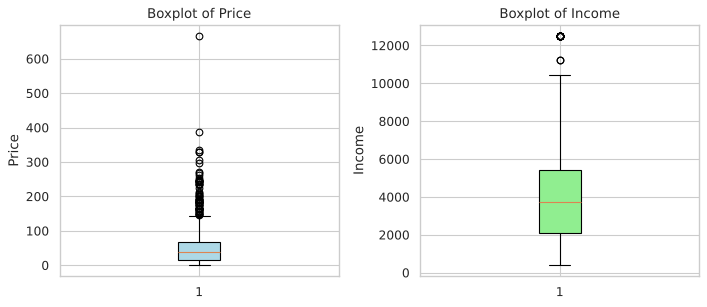

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].boxplot(df_clean["price"], patch_artist=True, boxprops=dict(facecolor="lightblue"))
axes[0].set_title("Boxplot of Price"); axes[0].set_ylabel("Price")
axes[1].boxplot(df_clean["income"], patch_artist=True, boxprops=dict(facecolor="lightgreen"))
axes[1].set_title("Boxplot of Income"); axes[1].set_ylabel("Income")
plt.tight_layout(); plt.show()

**Q15. Identify outliers using the IQR method.**

In [48]:
Q1 = df_clean["price"].quantile(0.25)
Q3 = df_clean["price"].quantile(0.75)
IQR_val = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR_val
upper_bound = Q3 + 1.5 * IQR_val
print("Lower bound:", lower_bound, " Upper bound:", upper_bound)
outliers_price = df_clean[(df_clean["price"] < lower_bound) | (df_clean["price"] > upper_bound)]
print(len(outliers_price))
outliers_price.head()

Lower bound: -61.59450000000002  Upper bound: 144.97750000000002
67
     rownames     mode    price   catch   pbeach    ppier    pboat  pcharter  cbeach   cpier   cboat  ccharter     income mode_upper mode_lower
0           1  charter  182.930  0.5391  157.930  157.930  157.930   182.930  0.0678  0.0503  0.2601    0.5391  7083.3317    CHARTER    charter
43         44  charter  211.208  2.3101   59.248   59.248  186.208   211.208  0.2537  0.1498  0.7369    2.3101  3749.9999    CHARTER    charter
105       106  charter  181.770  0.3975  268.702  268.702  146.770   181.770  0.5333  0.4522  0.1665    0.3975  8750.0010    CHARTER    charter
106       107  charter  246.102  2.3014   55.740   55.740  221.102   246.102  0.2537  0.1498  0.6817    2.3014  7083.3317    CHARTER    charter
119       120  charter  296.552  0.0041  135.634  135.634  267.552   296.552  0.0678  0.0789  0.1643    0.0041  7083.3317    CHARTER    charter


**Q16. Remove extreme outliers.**

In [49]:
df_no_outliers = df_clean[(df_clean["price"] >= lower_bound) & (df_clean["price"] <= upper_bound)]
print(df_clean.shape)
print(df_no_outliers.shape)
df_clean = df_no_outliers

(1182, 15)
(1115, 15)


**Q17. Histogram of a numerical variable.**

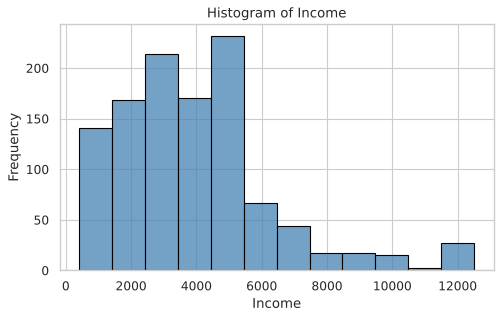

In [50]:
plt.figure(figsize=(7, 4))
sns.histplot(df_clean["income"], binwidth=1000, color="steelblue", edgecolor="black")
plt.title("Histogram of Income"); plt.xlabel("Income"); plt.ylabel("Frequency")
plt.show()

**Q18. Add a density curve to the histogram.**

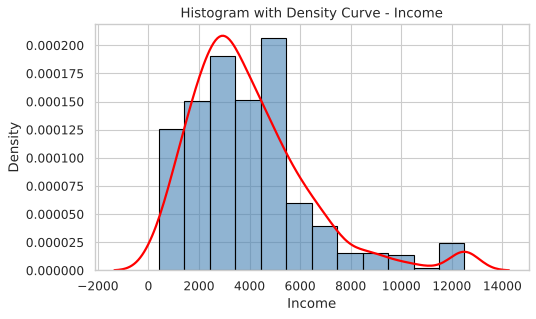

In [51]:
plt.figure(figsize=(7, 4))
sns.histplot(df_clean["income"], binwidth=1000, stat="density", color="steelblue", edgecolor="black", alpha=0.6)
sns.kdeplot(df_clean["income"], color="red", linewidth=2)
plt.title("Histogram with Density Curve - Income"); plt.xlabel("Income"); plt.ylabel("Density")
plt.show()

**Q19. Violin plot.**

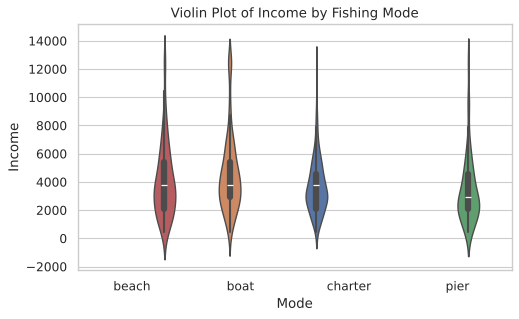

In [52]:
plt.figure(figsize=(7, 4))
sns.violinplot(data=df_clean, x="mode", y="income", hue="mode", legend=False)
plt.title("Violin Plot of Income by Fishing Mode"); plt.xlabel("Mode"); plt.ylabel("Income")
plt.show()

**Q20. Dot plot for a small numerical sample.**

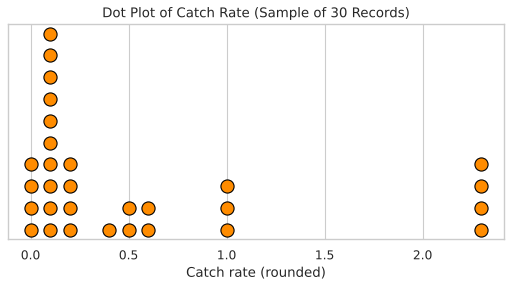

In [53]:
small_sample = df_clean.sample(n=30, random_state=1)
counts = small_sample["catch"].round(1).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3.5))
for val, n in counts.items():
    ax.scatter([val] * n, range(1, n + 1), s=140, color="darkorange", edgecolor="black")
ax.set_title("Dot Plot of Catch Rate (Sample of 30 Records)")
ax.set_xlabel("Catch rate (rounded)"); ax.set_yticks([])
plt.show()

**Q21. Frequency table for a categorical variable.**

In [54]:
freq_table = df_clean["mode"].value_counts()
freq_table

mode
charter    410
boat       398
pier       175
beach      132


**Q22. Proportion and percentage of each category.**

In [55]:
prop_table = freq_table / freq_table.sum()
pd.DataFrame({"Category": freq_table.index, "Frequency": freq_table.values,
    "Proportion": prop_table.round(4).values, "Percentage": (prop_table * 100).round(2).values})

  Category  Frequency  Proportion  Percentage
0  charter        410      0.3677       36.77
1     boat        398      0.3570       35.70
2     pier        175      0.1570       15.70
3    beach        132      0.1184       11.84


**Q23. Bar chart of frequencies.**

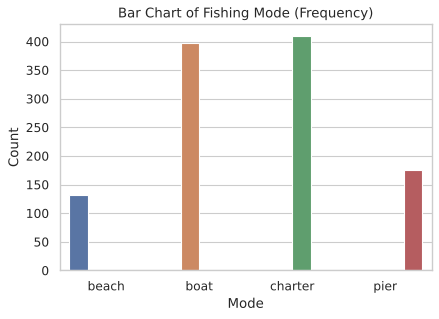

In [56]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df_clean, x="mode", hue="mode", legend=False)
plt.title("Bar Chart of Fishing Mode (Frequency)"); plt.xlabel("Mode"); plt.ylabel("Count")
plt.show()

**Q24. Horizontal bar chart.**

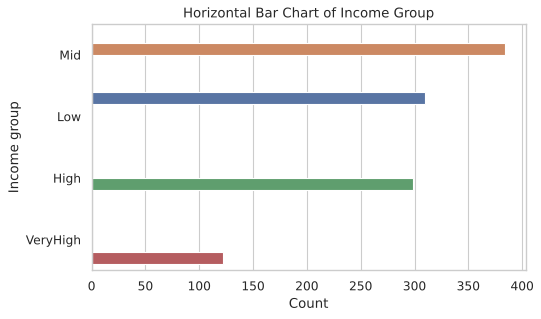

In [57]:
df_clean["income_group"] = pd.cut(df_clean["income"], bins=[0, 2500, 4500, 6500, np.inf],
    labels=["Low", "Mid", "High", "VeryHigh"])
order = df_clean["income_group"].value_counts().index
plt.figure(figsize=(7, 4))
sns.countplot(data=df_clean, y="income_group", order=order, hue="income_group", legend=False)
plt.title("Horizontal Bar Chart of Income Group"); plt.xlabel("Count"); plt.ylabel("Income group")
plt.show()

**Q25. Percentage bar chart.**

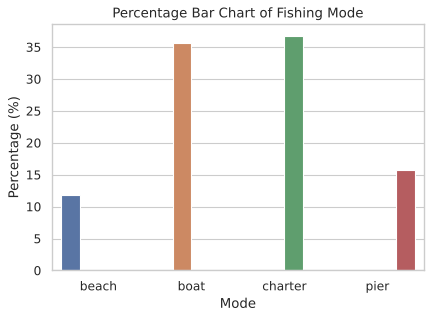

In [58]:
pct = df_clean["mode"].value_counts(normalize=True) * 100
plt.figure(figsize=(6, 4))
sns.barplot(x=pct.index, y=pct.values, hue=pct.index, legend=False)
plt.title("Percentage Bar Chart of Fishing Mode"); plt.xlabel("Mode"); plt.ylabel("Percentage (%)")
plt.show()

**Q26. Pie chart.**

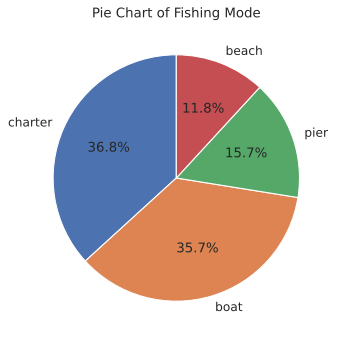

In [59]:
pie_data = df_clean["mode"].value_counts()
plt.figure(figsize=(5, 5))
plt.pie(pie_data.values, labels=pie_data.index, autopct="%1.1f%%", startangle=90)
plt.title("Pie Chart of Fishing Mode")
plt.show()

**Q27. Lollipop chart.**

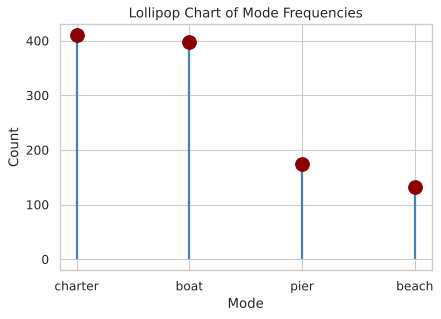

In [60]:
lp = df_clean["mode"].value_counts()
plt.figure(figsize=(6, 4))
plt.vlines(lp.index.astype(str), 0, lp.values, color="steelblue", linewidth=2)
plt.scatter(lp.index.astype(str), lp.values, s=150, color="darkred", zorder=3)
plt.title("Lollipop Chart of Mode Frequencies"); plt.xlabel("Mode"); plt.ylabel("Count")
plt.show()

**Q28. Dot chart.**

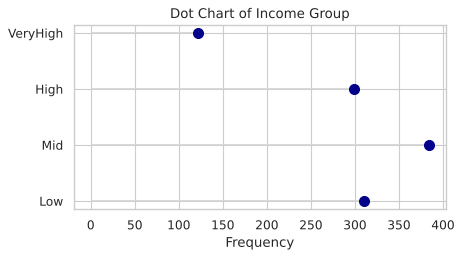

In [61]:
t = df_clean["income_group"].value_counts().sort_index()
plt.figure(figsize=(6, 3))
plt.hlines(t.index.astype(str), 0, t.values, color="lightgray")
plt.scatter(t.values, t.index.astype(str), color="darkblue", s=80, zorder=3)
plt.title("Dot Chart of Income Group"); plt.xlabel("Frequency")
plt.show()

**Q29. Density plot.**

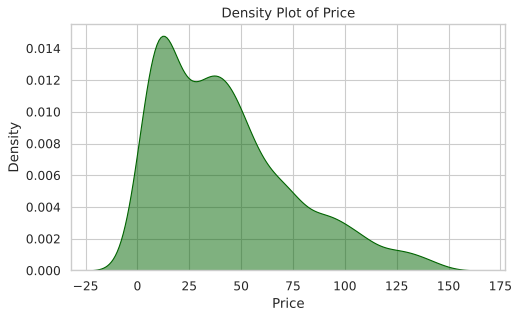

In [62]:
plt.figure(figsize=(7, 4))
sns.kdeplot(df_clean["price"], fill=True, color="darkgreen", alpha=0.5)
plt.title("Density Plot of Price"); plt.xlabel("Price"); plt.ylabel("Density")
plt.show()

**Q30. Faceting — distribution of one variable across groups.**

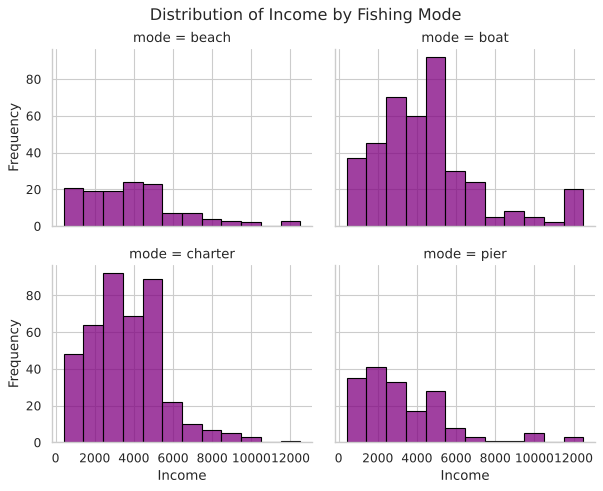

In [63]:
g = sns.FacetGrid(df_clean, col="mode", col_wrap=2, height=3, aspect=1.3)
g.map_dataframe(sns.histplot, x="income", binwidth=1000, color="purple", edgecolor="black")
g.set_axis_labels("Income", "Frequency")
g.figure.suptitle("Distribution of Income by Fishing Mode", y=1.02)
plt.show()

## ASSESSMENT V — Multivariate Analysis

**Q1. Load the dataset; identify numerical and categorical variables.**

In [64]:
gss = pd.read_csv(data_path)
print(gss.shape)
gss.info()
display(gss.head())
display(gss.describe(include="all").round(3))
gss["mode"] = gss["mode"].astype("category")
gss["income_group"] = pd.cut(gss["income"], bins=[0, 2500, 4500, 6500, np.inf], labels=["Low", "Mid", "High", "VeryHigh"])
gss["price_level"] = pd.qcut(gss["price"], 2, labels=["Cheap", "Expensive"])
numerical_vars = list(gss.select_dtypes(include="number").columns)
categorical_vars = list(gss.select_dtypes(include="category").columns)
print("\nNumerical variables:", numerical_vars)
print("Categorical variables:", categorical_vars)

(1182, 13)
<class 'pandas.DataFrame'>
RangeIndex: 1182 entries, 0 to 1181
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   rownames  1182 non-null   int64  
 1   mode      1182 non-null   str    
 2   price     1182 non-null   float64
 3   catch     1182 non-null   float64
 4   pbeach    1182 non-null   float64
 5   ppier     1182 non-null   float64
 6   pboat     1182 non-null   float64
 7   pcharter  1182 non-null   float64
 8   cbeach    1182 non-null   float64
 9   cpier     1182 non-null   float64
 10  cboat     1182 non-null   float64
 11  ccharter  1182 non-null   float64
 12  income    1182 non-null   float64
dtypes: float64(11), int64(1), str(1)
memory usage: 120.2 KB
   rownames     mode    price   catch   pbeach    ppier    pboat  pcharter  cbeach   cpier   cboat  ccharter     income
0         1  charter  182.930  0.5391  157.930  157.930  157.930   182.930  0.0678  0.0503  0.2601    0.5391  7083.3317
1      

**Q2. Scatter plot with three variables (x, y, colour).**

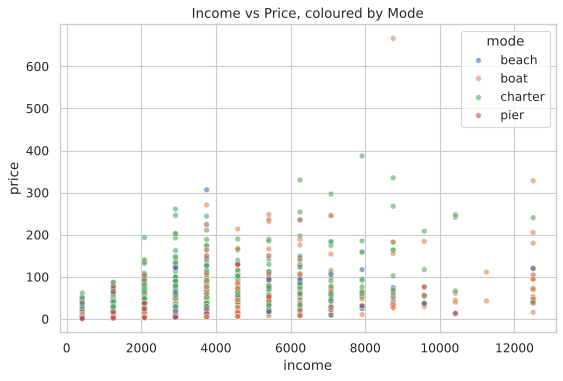

In [65]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=gss, x="income", y="price", hue="mode", alpha=0.6, s=25)
plt.title("Income vs Price, coloured by Mode")
plt.show()

**Q3. Scatter plot with four variables (x, y, colour, shape).**

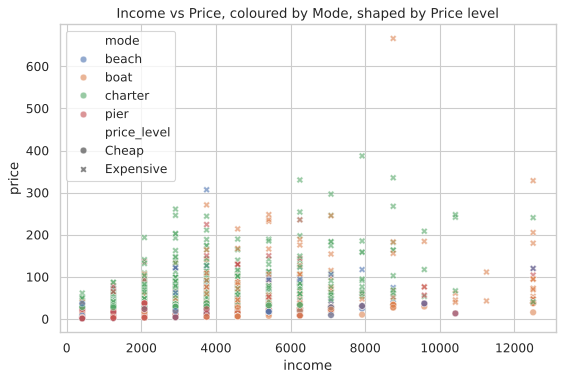

In [66]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=gss, x="income", y="price", hue="mode", style="price_level", alpha=0.6, s=35)
plt.title("Income vs Price, coloured by Mode, shaped by Price level")
plt.show()

**Q4. Scatter plot with four variables (x, y, colour, size).**

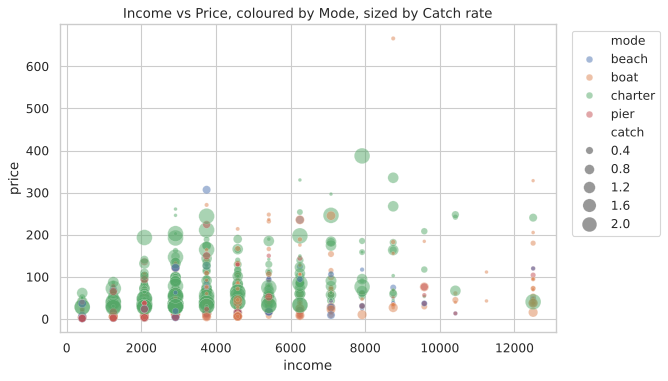

In [67]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=gss, x="income", y="price", hue="mode", size="catch", sizes=(10, 200), alpha=0.5)
plt.title("Income vs Price, coloured by Mode, sized by Catch rate")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

**Q5. Bubble plot using three numerical variables.**

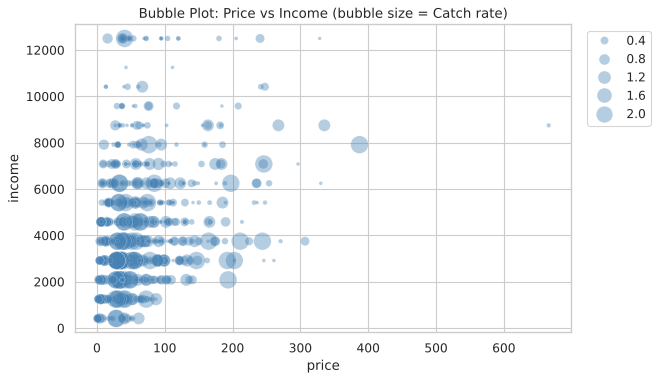

In [68]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=gss, x="price", y="income", size="catch", sizes=(10, 250), alpha=0.4, color="steelblue")
plt.title("Bubble Plot: Price vs Income (bubble size = Catch rate)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

**Q6. Subplots using faceting by one variable.**

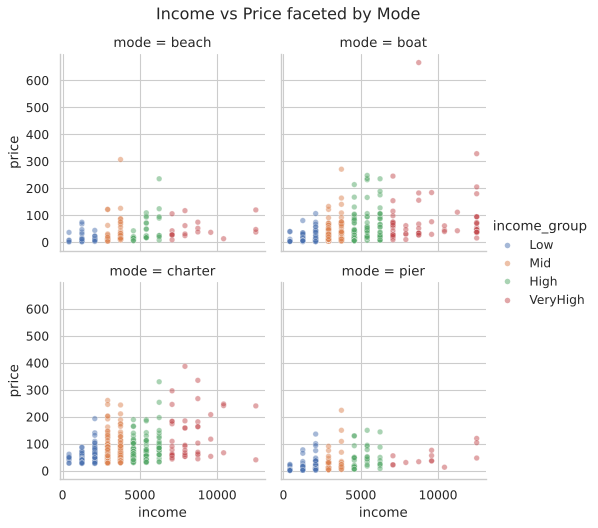

In [69]:
g = sns.relplot(data=gss, x="income", y="price", hue="income_group", col="mode", col_wrap=2, alpha=0.5, s=25, height=3.2)
g.figure.suptitle("Income vs Price faceted by Mode", y=1.03)
plt.show()

**Q7. Subplots using a facet grid (two categorical variables).**

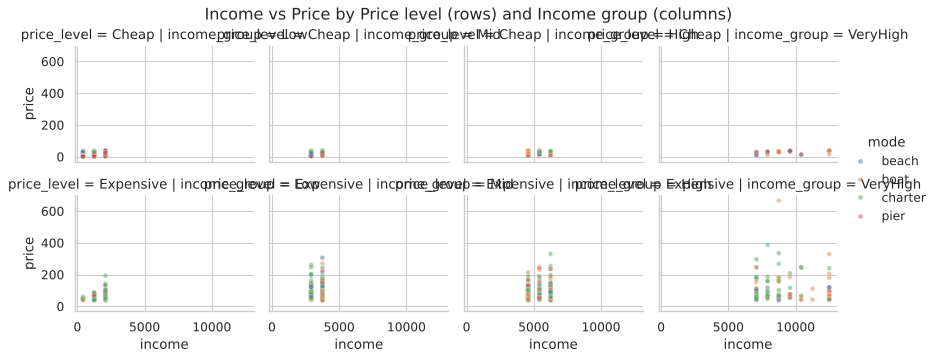

In [70]:
g = sns.relplot(data=gss, x="income", y="price", hue="mode", row="price_level", col="income_group", alpha=0.5, s=18, height=2.2, aspect=1.2)
g.figure.suptitle("Income vs Price by Price level (rows) and Income group (columns)", y=1.02)
plt.show()

**Q8. Pairs plot using at least four numerical variables.**

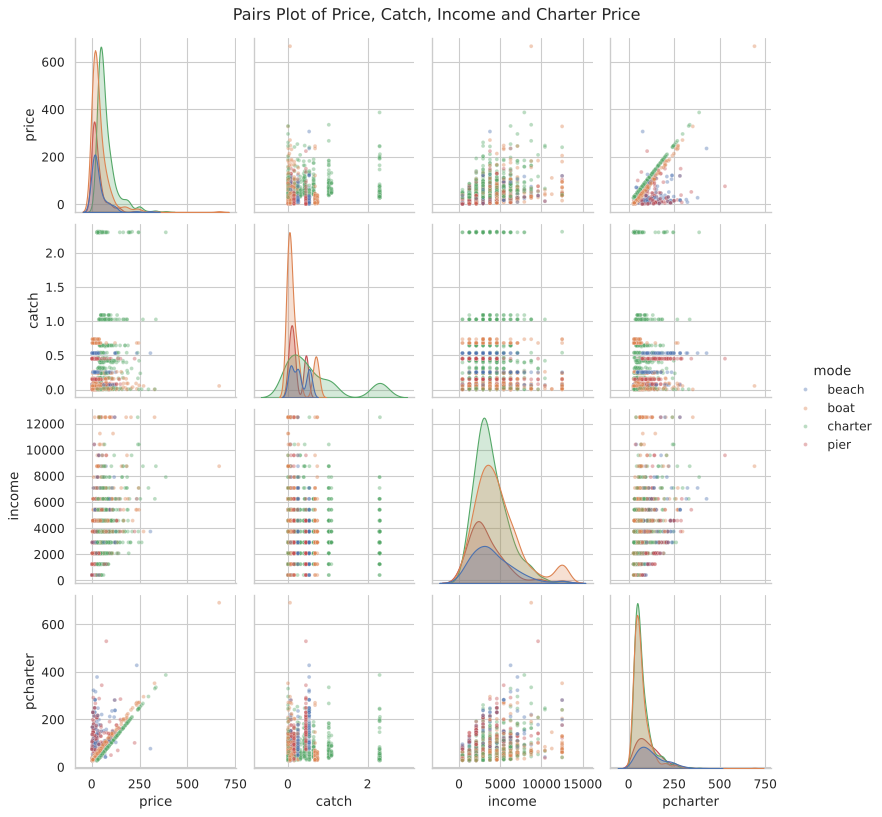

In [71]:
g = sns.pairplot(gss, vars=["price", "catch", "income", "pcharter"], hue="mode", plot_kws=dict(alpha=0.4, s=12))
g.figure.suptitle("Pairs Plot of Price, Catch, Income and Charter Price", y=1.02)
plt.show()

**Q9. Parallel coordinate plot.**

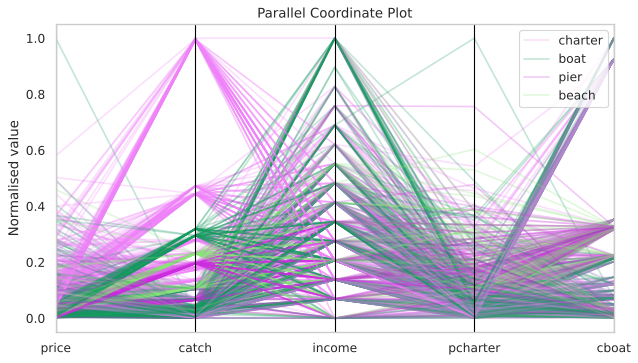

In [72]:
from pandas.plotting import parallel_coordinates
pc = gss[["price", "catch", "income", "pcharter", "cboat"]].copy()
pc = (pc - pc.min()) / (pc.max() - pc.min())
pc["mode"] = gss["mode"].astype(str).values
plt.figure(figsize=(9, 5))
parallel_coordinates(pc, "mode", alpha=0.25)
plt.title("Parallel Coordinate Plot"); plt.ylabel("Normalised value")
plt.show()

## ASSESSMENT VI — Time Series Analysis

**Note: the Fishing dataset is cross-sectional (no time variable), so the classic AirPassengers monthly series (1949-1960) is embedded, exactly as in the original lab.**

In [73]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX

**Q1. Load the AirPassengers dataset.**

In [74]:
ap_values = [
 112,118,132,129,121,135,148,148,136,119,104,118,
 115,126,141,135,125,149,170,170,158,133,114,140,
 145,150,178,163,172,178,199,199,184,162,146,166,
 171,180,193,181,183,218,230,242,209,191,172,194,
 196,196,236,235,229,243,264,272,237,211,180,201,
 204,188,235,227,234,264,302,293,259,229,203,229,
 242,233,267,269,270,315,364,347,312,274,237,278,
 284,277,317,313,318,374,413,405,355,306,271,306,
 315,301,356,348,355,422,465,467,404,347,305,336,
 340,318,362,348,363,435,491,505,404,359,310,337,
 360,342,406,396,420,472,548,559,463,407,362,405,
 417,391,419,461,472,535,622,606,508,461,390,432]
ap = pd.Series(ap_values, index=pd.date_range("1949-01-01", periods=144, freq="MS"), name="AirPassengers")

**Q2. First five and last five observations.**

In [75]:
print(ap.head(5)); print(); print(ap.tail(5))

1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: AirPassengers, dtype: int64

1960-08-01    606
1960-09-01    508
1960-10-01    461
1960-11-01    390
1960-12-01    432
Freq: MS, Name: AirPassengers, dtype: int64


**Q3. Starting and ending time periods.**

In [76]:
print("Start period:", (ap.index[0].year, ap.index[0].month))
print("End period:", (ap.index[-1].year, ap.index[-1].month))

Start period: (1949, 1)
End period: (1960, 12)


**Q4. Frequency and time-series characteristics.**

In [77]:
print("Frequency:", 12, "(monthly)")
print("Index type:", type(ap.index).__name__)
print(ap.describe())

Frequency: 12 (monthly)
Index type: DatetimeIndex
count    144.000000
mean     280.298611
std      119.966317
min      104.000000
25%      180.000000
50%      265.500000
75%      360.500000
max      622.000000
Name: AirPassengers, dtype: float64


**Q5. Visualize the monthly passenger trend.**

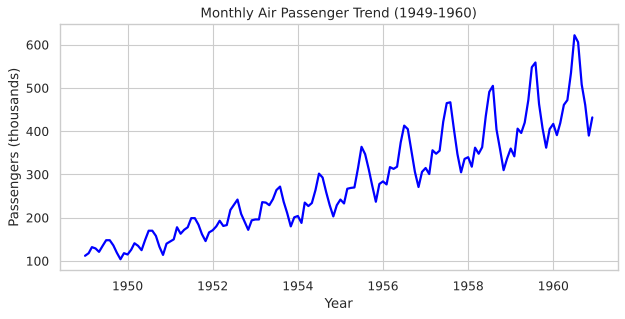

In [78]:
plt.figure(figsize=(9, 4))
plt.plot(ap, color="blue", linewidth=2)
plt.title("Monthly Air Passenger Trend (1949-1960)")
plt.xlabel("Year"); plt.ylabel("Passengers (thousands)"); plt.grid(True)
plt.show()

**Q6. Decompose into trend, seasonal and random components (multiplicative).**

In [79]:
decomposed_ap = seasonal_decompose(ap, model="multiplicative", period=12)
print(decomposed_ap.seasonal.head(12).round(4))
print(decomposed_ap.trend.head(12))
print(decomposed_ap.resid.head(12))

1949-01-01    0.9102
1949-02-01    0.8836
1949-03-01    1.0074
1949-04-01    0.9759
1949-05-01    0.9814
1949-06-01    1.1128
1949-07-01    1.2266
1949-08-01    1.2199
1949-09-01    1.0605
1949-10-01    0.9218
1949-11-01    0.8012
1949-12-01    0.8988
Freq: MS, Name: seasonal, dtype: float64
1949-01-01           NaN
1949-02-01           NaN
1949-03-01           NaN
1949-04-01           NaN
1949-05-01           NaN
1949-06-01           NaN
1949-07-01    126.791667
1949-08-01    127.250000
1949-09-01    127.958333
1949-10-01    128.583333
1949-11-01    129.000000
1949-12-01    129.750000
Freq: MS, Name: trend, dtype: float64
1949-01-01         NaN
1949-02-01         NaN
1949-03-01         NaN
1949-04-01         NaN
1949-05-01         NaN
1949-06-01         NaN
1949-07-01    0.951664
1949-08-01    0.953401
1949-09-01    1.002220
1949-10-01    1.004028
1949-11-01    1.006270
1949-12-01    1.011812
Freq: MS, Name: resid, dtype: float64


**Q7. Plot the decomposed components.**

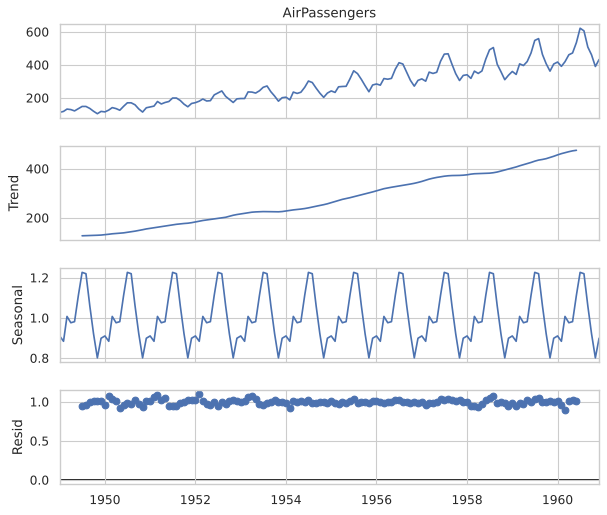

In [80]:
fig = decomposed_ap.plot(); fig.set_size_inches(8, 7)
plt.show()

**Q8. ACF and PACF.**

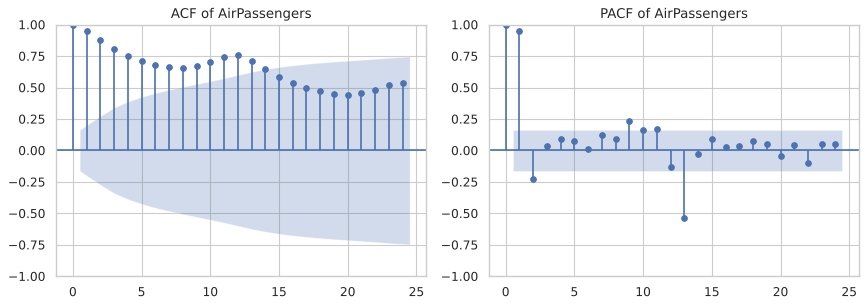

In [81]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_acf(ap, lags=24, ax=axes[0]); axes[0].set_title("ACF of AirPassengers")
plot_pacf(ap, lags=24, ax=axes[1]); axes[1].set_title("PACF of AirPassengers")
plt.tight_layout(); plt.show()

**Q9. Fit an ARIMA model (grid search on AIC, since Python has no auto.arima).**

In [82]:
best_model, best_aic, best_cfg = None, np.inf, None
for p, q, P, Q in itertools.product(range(3), range(3), range(2), range(2)):
    try:
        m = SARIMAX(ap, order=(p, 1, q), seasonal_order=(P, 1, Q, 12),
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    except Exception:
        continue
    if m.aic < best_aic:
        best_model, best_aic, best_cfg = m, m.aic, ((p, 1, q), (P, 1, Q, 12))
arima_model = best_model
print("Best model: ARIMA%s x %s  (AIC = %.2f)" % (best_cfg[0], best_cfg[1], best_aic))

Best model: ARIMA(2, 1, 2) x (0, 1, 1, 12)  (AIC = 911.70)


**Q10. Display and interpret the fitted ARIMA model.**

In [83]:
print(arima_model.summary())
print("AIC:", round(arima_model.aic, 2), "| BIC:", round(arima_model.bic, 2), "| Log-likelihood:", round(arima_model.llf, 2))

                                      SARIMAX Results                                       
Dep. Variable:                        AirPassengers   No. Observations:                  144
Model:             SARIMAX(2, 1, 2)x(0, 1, [1], 12)   Log Likelihood                -449.849
Date:                              Sun, 01 Nov 2026   AIC                            911.698
Time:                                      17:33:31   BIC                            928.220
Sample:                                  01-01-1949   HQIC                           918.405
                                       - 12-01-1960                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3828      0.436      0.879      0.379      -0.471       1.236
ar.L2          0.36

**Q11. Forecast the next 12 months.**

In [84]:
fc = arima_model.get_forecast(steps=12)
forecast_mean = fc.predicted_mean
print(forecast_mean.round(2))
print(fc.se_mean.round(2))

1961-01-01    444.22
1961-02-01    420.12
1961-03-01    451.84
1961-04-01    488.81
1961-05-01    501.30
1961-06-01    563.61
1961-07-01    649.40
1961-08-01    636.42
1961-09-01    538.75
1961-10-01    491.02
1961-11-01    422.80
1961-12-01    464.81
Freq: MS, Name: predicted_mean, dtype: float64
1961-01-01    11.62
1961-02-01    13.60
1961-03-01    15.32
1961-04-01    16.24
1961-05-01    16.92
1961-06-01    17.36
1961-07-01    17.67
1961-08-01    17.89
1961-09-01    18.04
1961-10-01    18.16
1961-11-01    18.24
1961-12-01    18.30
Freq: MS, Name: var_pred_mean, dtype: float64


**Q12. Actual vs forecasted values.**

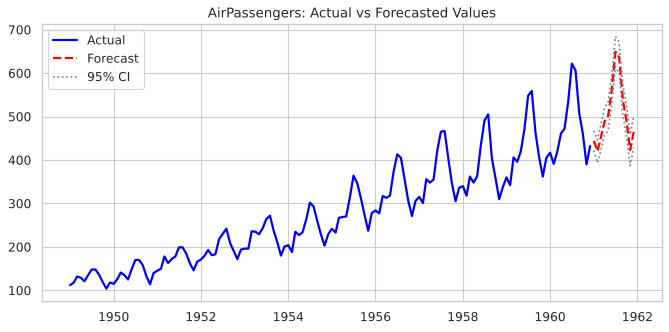

In [85]:
ci = fc.conf_int(alpha=0.05)
plt.figure(figsize=(10, 4.5))
plt.plot(ap, color="blue", linewidth=2, label="Actual")
plt.plot(forecast_mean, color="red", linestyle="--", linewidth=2, label="Forecast")
plt.plot(ci.index, ci.iloc[:, 0], color="gray", linestyle=":", label="95% CI")
plt.plot(ci.index, ci.iloc[:, 1], color="gray", linestyle=":")
plt.title("AirPassengers: Actual vs Forecasted Values"); plt.legend(loc="upper left")
plt.show()

## ASSESSMENT VII — 1D, 2D and ND Analysis

**Q1. Load the dataset.**

In [86]:
data = pd.read_csv(data_path)
display(data.head())
data.info()
print(data.shape)
print(list(data.columns))

   rownames     mode    price   catch   pbeach    ppier    pboat  pcharter  cbeach   cpier   cboat  ccharter     income
0         1  charter  182.930  0.5391  157.930  157.930  157.930   182.930  0.0678  0.0503  0.2601    0.5391  7083.3317
1         2  charter   34.534  0.4671   15.114   15.114   10.534    34.534  0.1049  0.0451  0.1574    0.4671  1249.9998
2         3     boat   24.334  0.2413  161.874  161.874   24.334    59.334  0.5333  0.4522  0.2413    1.0266  3749.9999
3         4     pier   15.134  0.0789   15.134   15.134   55.930    84.930  0.0678  0.0789  0.1643    0.5391  2083.3332
4         5     boat   41.514  0.1082  106.930  106.930   41.514    71.014  0.0678  0.0503  0.1082    0.3240  4583.3320
<class 'pandas.DataFrame'>
RangeIndex: 1182 entries, 0 to 1181
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   rownames  1182 non-null   int64  
 1   mode      1182 non-null   str    
 2   price     1182 non-null

**Q2. Missing values and duplicates check.**

In [87]:
print(data.isna().sum())
print("Duplicated rows:", data.duplicated().sum())

rownames    0
mode        0
price       0
catch       0
pbeach      0
ppier       0
pboat       0
pcharter    0
cbeach      0
cpier       0
cboat       0
ccharter    0
income      0
dtype: int64
Duplicated rows: 0


**Q3. Summary statistics of income stored in a data frame.**

In [88]:
x = data["income"]
summary_statistics = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Minimum", "Maximum", "Range", "Variance", "Standard Deviation", "IQR", "Skewness", "Kurtosis"],
    "Value": [x.mean(), x.median(), x.min(), x.max(), x.max() - x.min(), x.var(ddof=1), x.std(ddof=1),
              x.quantile(0.75) - x.quantile(0.25), skewness(x), kurtosis(x)]})
print(summary_statistics)

            Statistic         Value
0                Mean  4.099337e+03
1              Median  3.750000e+03
2             Minimum  4.166667e+02
3             Maximum  1.250000e+04
4               Range  1.208333e+04
5            Variance  6.061267e+06
6  Standard Deviation  2.461964e+03
7                 IQR  3.333333e+03
8            Skewness  1.304414e+00
9            Kurtosis  2.091439e+00


**Q4. Frequency / relative frequency tables, pie chart and bar plot for a categorical variable.**

mode
charter    452
boat       418
pier       178
beach      134
Name: count, dtype: int64
mode
charter    0.382403
boat       0.353638
pier       0.150592
beach      0.113367
Name: count, dtype: float64
mode
charter    38.240271
boat       35.363790
pier       15.059222
beach      11.336717
Name: count, dtype: float64


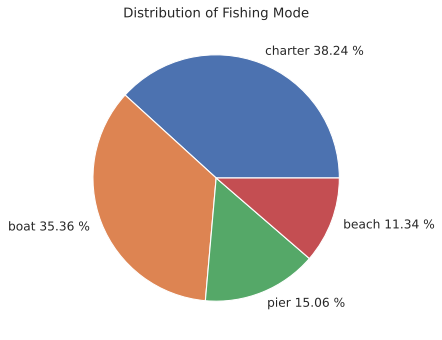

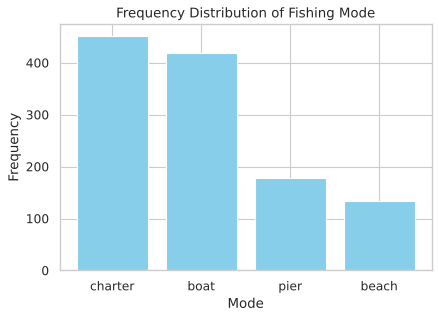

In [89]:
freq_mode = data["mode"].value_counts()
print(freq_mode); print(freq_mode / freq_mode.sum()); print(freq_mode / freq_mode.sum() * 100)
plt.figure(figsize=(5, 5))
plt.pie(freq_mode.values, labels=[f"{k} {v:.2f} %" for k, v in zip(freq_mode.index, freq_mode / freq_mode.sum() * 100)])
plt.title("Distribution of Fishing Mode")
plt.show()
plt.figure(figsize=(6, 4))
plt.bar(freq_mode.index.astype(str), freq_mode.values, color="skyblue")
plt.title("Frequency Distribution of Fishing Mode"); plt.xlabel("Mode"); plt.ylabel("Frequency")
plt.show()

**Q5. Binned frequency table, histogram and box plot for a numerical variable.**

income
[0, 2000)         141
[2000, 4000)      573
[4000, 6000)      244
[6000, 8000)      147
[8000, 10000)      36
[10000, 12000)     10
[12000, 14000)     31
Name: count, dtype: int64
income
[0, 2000)         0.119289
[2000, 4000)      0.484772
[4000, 6000)      0.206430
[6000, 8000)      0.124365
[8000, 10000)     0.030457
[10000, 12000)    0.008460
[12000, 14000)    0.026227
Name: count, dtype: float64


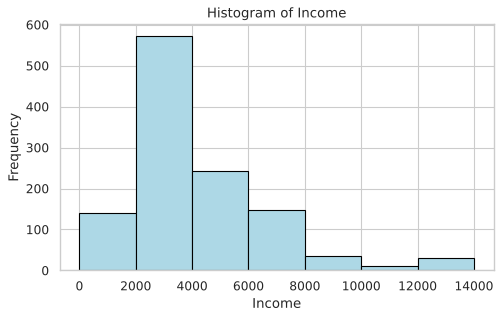

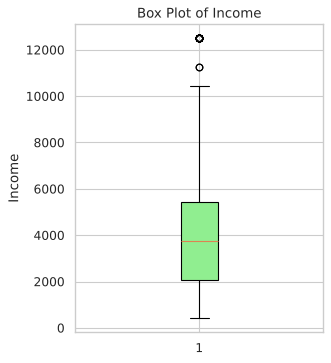

In [90]:
breaks = np.arange(0, math.ceil(data["income"].max() / 2000) * 2000 + 1, 2000)
groups = pd.cut(data["income"], bins=breaks, right=False, include_lowest=True)
inc_freq = groups.value_counts().sort_index()
print(inc_freq); print(inc_freq / inc_freq.sum())
plt.figure(figsize=(7, 4))
plt.hist(data["income"], bins=breaks, color="lightblue", edgecolor="black")
plt.title("Histogram of Income"); plt.xlabel("Income"); plt.ylabel("Frequency")
plt.show()
plt.figure(figsize=(4, 5))
plt.boxplot(data["income"], patch_artist=True, boxprops=dict(facecolor="lightgreen"))
plt.title("Box Plot of Income"); plt.ylabel("Income")
plt.show()

**Q6. Contingency table and row / column percentages.**

In [91]:
data["income_group"] = pd.cut(data["income"], bins=[0, 2500, 4500, 6500, np.inf], labels=["Low", "Mid", "High", "VeryHigh"])
contingency_table = pd.crosstab(data["mode"], data["income_group"])
print(contingency_table)
print(pd.crosstab(data["mode"], data["income_group"], normalize="index") * 100)
print(pd.crosstab(data["mode"], data["income_group"], normalize="columns") * 100)
print(pd.crosstab(data["mode"], data["income_group"], normalize="all") * 100)

income_group  Low  Mid  High  VeryHigh
mode                                  
beach          40   44    31        19
boat           82  132   131        73
charter       113  175   120        44
pier           76   52    37        13
income_group        Low        Mid       High   VeryHigh
mode                                                    
beach         29.850746  32.835821  23.134328  14.179104
boat          19.617225  31.578947  31.339713  17.464115
charter       25.000000  38.716814  26.548673   9.734513
pier          42.696629  29.213483  20.786517   7.303371
income_group        Low        Mid       High   VeryHigh
mode                                                    
beach         12.861736  10.918114   9.717868  12.751678
boat          26.366559  32.754342  41.065831  48.993289
charter       36.334405  43.424318  37.617555  29.530201
pier          24.437299  12.903226  11.598746   8.724832
income_group       Low        Mid       High  VeryHigh
mode                       

**Q7. Stacked bar plot.**

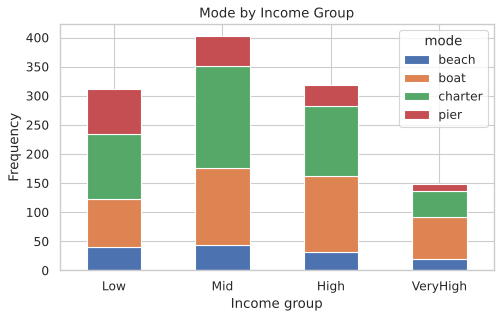

In [92]:
contingency_table.T.plot(kind="bar", stacked=True, figsize=(7, 4), rot=0)
plt.title("Mode by Income Group"); plt.xlabel("Income group"); plt.ylabel("Frequency")
plt.show()

**Q8. Mean, median and SD of a numerical variable grouped by category.**

In [93]:
grouped_statistics = data.groupby("mode")["income"].agg(Mean="mean", Median="median", SD="std").reset_index()
print(grouped_statistics)

      mode         Mean     Median           SD
0    beach  4051.616731  3749.9999  2505.419975
1     boat  4654.106543  3749.9999  2777.897964
2  charter  3880.899520  3749.9999  2050.028471
3     pier  3387.172123  2916.6666  2340.323663


**Q9. Side-by-side box plots and violin plot.**

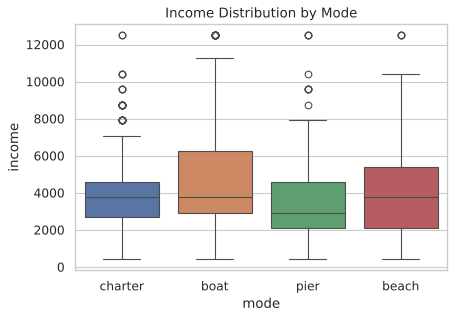

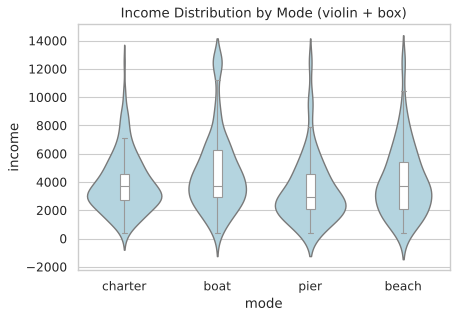

In [94]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=data, x="mode", y="income", hue="mode", legend=False)
plt.title("Income Distribution by Mode")
plt.show()
plt.figure(figsize=(6, 4))
sns.violinplot(data=data, x="mode", y="income", color="lightblue", inner=None)
sns.boxplot(data=data, x="mode", y="income", width=0.1, color="white", fliersize=0)
plt.title("Income Distribution by Mode (violin + box)")
plt.show()

**Q10. Pearson and Spearman correlation + scatter plot with linear trend line.**

     Method  Correlation
0   Pearson     0.315275
1  Spearman     0.357381


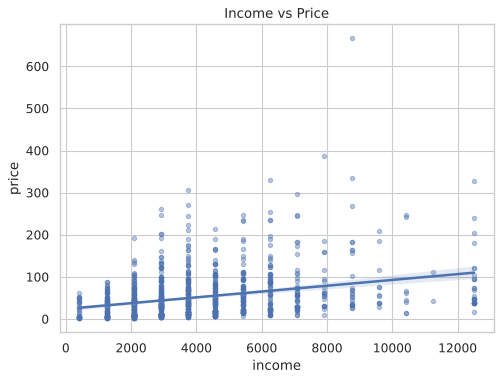

In [95]:
pair = data[["price", "income"]].dropna()
pearson_c = pair["price"].corr(pair["income"], method="pearson")
spearman_c = pair["price"].corr(pair["income"], method="spearman")
print(pd.DataFrame({"Method": ["Pearson", "Spearman"], "Correlation": [pearson_c, spearman_c]}))
plt.figure(figsize=(7, 5))
sns.regplot(data=data, x="income", y="price", scatter_kws=dict(alpha=0.4, s=15))
plt.title("Income vs Price")
plt.show()

**Q11. Summary statistics across two categorical variables; faceted box plot and grouped bar chart with error bars.**

       mode income_group        Mean         SD
0     beach          Low   16.508450  16.938054
1     beach          Mid   39.589500  53.007554
2     beach         High   47.005484  49.224595
3     beach     VeryHigh   48.646632  33.122221
4      boat          Low   17.813000  20.225960
5      boat          Mid   32.253500  36.598553
6      boat         High   48.380382  52.996400
7      boat     VeryHigh   73.091644  90.779779
8   charter          Low   53.481469  25.167503
9   charter          Mid   71.218651  46.235698
10  charter         High   80.354817  46.792342
11  charter     VeryHigh  131.694773  89.030302
12     pier          Low   19.040789  24.828151
13     pier          Mid   29.861000  39.199375
14     pier         High   48.254108  40.895764
15     pier     VeryHigh   50.494000  32.221904


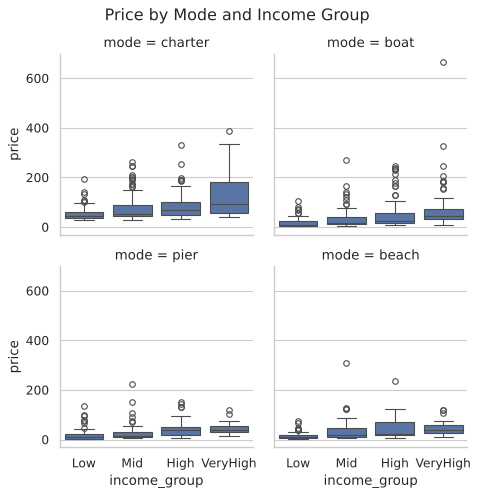

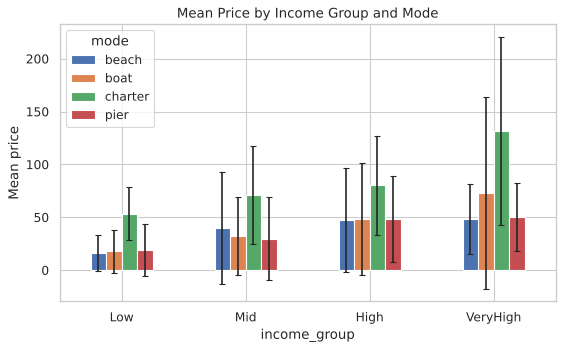

In [96]:
combination_summary = data.groupby(["mode", "income_group"])["price"].agg(Mean="mean", SD="std").reset_index()
print(combination_summary)
g = sns.catplot(data=data, x="income_group", y="price", col="mode", col_wrap=2, kind="box", height=3)
g.figure.suptitle("Price by Mode and Income Group", y=1.03)
plt.show()
means = combination_summary.pivot(index="income_group", columns="mode", values="Mean")
sds = combination_summary.pivot(index="income_group", columns="mode", values="SD")
means.plot(kind="bar", yerr=sds, capsize=3, figsize=(8, 4.5), rot=0)
plt.title("Mean Price by Income Group and Mode"); plt.ylabel("Mean price")
plt.show()

**Q12. Scatter plot coloured/shaped by category; correlation by category level.**

      mode  Pearson_Correlation  Spearman_Correlation
0    beach             0.296851              0.506470
1     boat             0.332717              0.495354
2  charter             0.409922              0.386929
3     pier             0.373115              0.508094


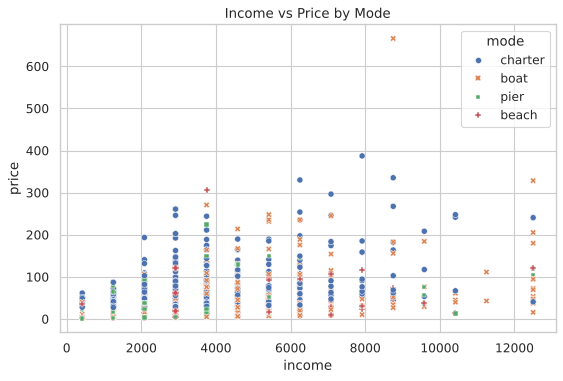

In [97]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=data, x="income", y="price", hue="mode", style="mode", s=30)
plt.title("Income vs Price by Mode")
plt.show()
cor_by_mode = data.groupby("mode").apply(lambda d: pd.Series({
    "Pearson_Correlation": d["income"].corr(d["price"], method="pearson"),
    "Spearman_Correlation": d["income"].corr(d["price"], method="spearman")})).reset_index()
print(cor_by_mode)

**Q13. Full correlation matrix and heatmap.**

          price  catch  pbeach  ppier  pboat  pcharter  cbeach  cpier  cboat  ccharter  income
price     1.000  0.107   0.404  0.404  0.634     0.637   0.034  0.007 -0.051    -0.020   0.315
catch     0.107  1.000  -0.026 -0.026 -0.005    -0.009   0.194  0.163  0.744     0.790  -0.083
pbeach    0.404 -0.026   1.000  1.000  0.112     0.141   0.332  0.226 -0.098    -0.027   0.527
ppier     0.404 -0.026   1.000  1.000  0.112     0.141   0.332  0.226 -0.098    -0.027   0.527
pboat     0.634 -0.005   0.112  0.112  1.000     0.996   0.213  0.253 -0.041    -0.023   0.320
pcharter  0.637 -0.009   0.141  0.141  0.996     1.000   0.245  0.287 -0.063    -0.027   0.316
cbeach    0.034  0.194   0.332  0.332  0.213     0.245   1.000  0.818  0.139     0.208  -0.072
cpier     0.007  0.163   0.226  0.226  0.253     0.287   0.818  1.000  0.134     0.187  -0.068
cboat    -0.051  0.744  -0.098 -0.098 -0.041    -0.063   0.139  0.134  1.000     0.936  -0.046
ccharter -0.020  0.790  -0.027 -0.027 -0.023    -0

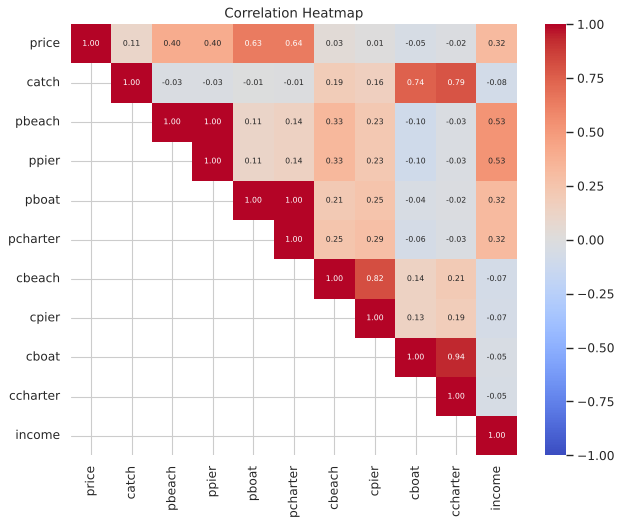

In [98]:
numeric_cols = ["price", "catch", "pbeach", "ppier", "pboat", "pcharter", "cbeach", "cpier", "cboat", "ccharter", "income"]
correlation_matrix = data[numeric_cols].corr()
print(correlation_matrix.round(3))
plt.figure(figsize=(9, 7))
mask = np.tril(np.ones_like(correlation_matrix, dtype=bool), k=-1)
sns.heatmap(correlation_matrix, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Correlation Heatmap")
plt.show()

**Q14. Pairs plot / scatterplot matrix and summary statistics of all numeric variables.**

    Variable      Mean    Median  Minimum    Maximum      Range     Variance        SD       IQR  Skewness  Kurtosis
0      price    52.082    37.896    1.290    666.110    664.820     2897.666    53.830    51.643     3.139    19.185
1      catch     0.389     0.164    0.000      2.310      2.310        0.314     0.561     0.497     2.346     5.231
2     pbeach   103.422    74.628    1.290    843.186    841.896    10741.466   103.641   117.488     1.870     4.969
3      ppier   103.422    74.628    1.290    843.186    841.896    10741.466   103.641   117.488     1.870     4.969
4      pboat    55.257    33.534    2.290    666.110    663.820     3932.976    62.713    59.280     2.650    12.263
5   pcharter    84.379    61.607   27.290    691.110    663.820     4037.922    63.545    59.878     2.592    11.637
6     cbeach     0.241     0.254    0.068      0.533      0.466        0.036     0.191     0.466     0.630    -1.239
7      cpier     0.162     0.079    0.001      0.452      0.451 

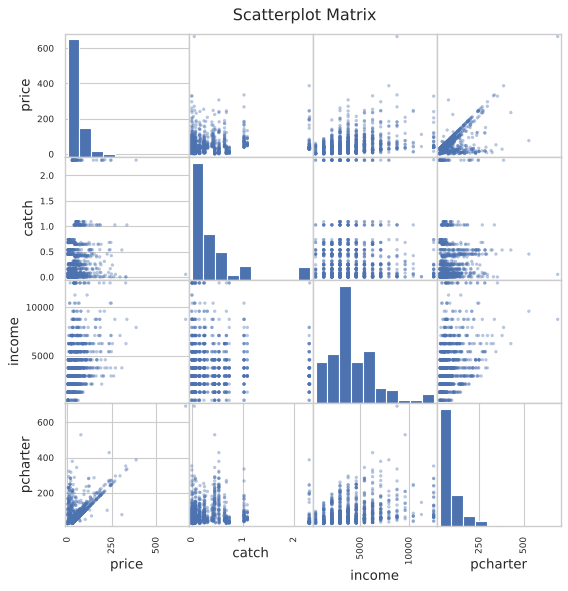

In [99]:
pd.plotting.scatter_matrix(data[["price", "catch", "income", "pcharter"]], figsize=(8, 8), alpha=0.4, diagonal="hist")
plt.suptitle("Scatterplot Matrix", y=0.92)
plt.show()

def summary_function(x):
    x = x.dropna()
    return pd.Series({"Mean": x.mean(), "Median": x.median(), "Minimum": x.min(), "Maximum": x.max(),
        "Range": x.max() - x.min(), "Variance": x.var(ddof=1), "SD": x.std(ddof=1),
        "IQR": x.quantile(0.75) - x.quantile(0.25), "Skewness": skewness(x), "Kurtosis": kurtosis(x)})

all_summary = data[numeric_cols].apply(summary_function).T
all_summary.insert(0, "Variable", all_summary.index)
print(all_summary.reset_index(drop=True).round(3).to_string())

## ASSESSMENT VIII — Clustering Techniques

### PART A: K-Means Clustering

In [100]:
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

**Q1. Load the dataset.**

In [101]:
data = pd.read_csv(data_path)

**Q2. View the dataset.**

In [102]:
display(data.head())
data.info()

   rownames     mode    price   catch   pbeach    ppier    pboat  pcharter  cbeach   cpier   cboat  ccharter     income
0         1  charter  182.930  0.5391  157.930  157.930  157.930   182.930  0.0678  0.0503  0.2601    0.5391  7083.3317
1         2  charter   34.534  0.4671   15.114   15.114   10.534    34.534  0.1049  0.0451  0.1574    0.4671  1249.9998
2         3     boat   24.334  0.2413  161.874  161.874   24.334    59.334  0.5333  0.4522  0.2413    1.0266  3749.9999
3         4     pier   15.134  0.0789   15.134   15.134   55.930    84.930  0.0678  0.0789  0.1643    0.5391  2083.3332
4         5     boat   41.514  0.1082  106.930  106.930   41.514    71.014  0.0678  0.0503  0.1082    0.3240  4583.3320
<class 'pandas.DataFrame'>
RangeIndex: 1182 entries, 0 to 1181
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   rownames  1182 non-null   int64  
 1   mode      1182 non-null   str    
 2   price     1182 non-null

**Q3. Check missing values.**

In [103]:
data.isna().sum()

rownames    0
mode        0
price       0
catch       0
pbeach      0
ppier       0
pboat       0
pcharter    0
cbeach      0
cpier       0
cboat       0
ccharter    0
income      0


**Q4. Distribution of categorical variables.**

In [104]:
print(data["mode"].value_counts())

mode
charter    452
boat       418
pier       178
beach      134
Name: count, dtype: int64


**Q5. Select only numerical features for K-Means.**

In [105]:
numeric_data = data.select_dtypes(include="number").drop(columns=["rownames"], errors="ignore").dropna()
print(numeric_data.shape)

(1182, 11)


**Q6. Standardize the data.**

In [106]:
scaled_data = scale(numeric_data)
scaled_data.head().round(4)

    price   catch  pbeach   ppier   pboat  pcharter  cbeach   cpier   cboat  ccharter  income
0  2.4308  0.2671  0.5259  0.5259  1.6372    1.5509 -0.9080 -0.6978  0.4237   -0.1278  1.2120
1 -0.3260  0.1387 -0.8521 -0.8521 -0.7131   -0.7844 -0.7135 -0.7302 -0.0659   -0.2298 -1.1573
2 -0.5155 -0.2641  0.5640  0.5640 -0.4931   -0.3941  1.5323  1.8079  0.3341    0.5626 -0.1419
3 -0.6864 -0.5538 -0.8519 -0.8519  0.0107    0.0087 -0.9080 -0.5195 -0.0330   -0.1278 -0.8189
4 -0.1963 -0.5016  0.0338  0.0338 -0.2191   -0.2103 -0.9080 -0.6978 -0.3004   -0.4325  0.1966


**Q7. K-Means with 2 centres.**

In [107]:
kmeans_2 = KMeans(n_clusters=2, n_init=25, random_state=123).fit(scaled_data)

**Q8. Display K-Means results.**

In [108]:
print("Cluster assignments:", kmeans_2.labels_)
print(pd.Series(kmeans_2.labels_).value_counts().sort_index())
print("Within-cluster sum of squares:", kmeans_2.inertia_)

Cluster assignments: [0 0 1 ... 1 1 1]
0    767
1    415
Name: count, dtype: int64
Within-cluster sum of squares: 10154.632765076494


**Q9. Cluster centres.**

In [109]:
pd.DataFrame(kmeans_2.cluster_centers_, columns=scaled_data.columns, index=[1, 2]).round(3)

   price  catch  pbeach  ppier  pboat  pcharter  cbeach  cpier  cboat  ccharter  income
1 -0.045 -0.391  -0.203 -0.203 -0.127    -0.147  -0.557 -0.573 -0.421    -0.453   0.036
2  0.083  0.722   0.376  0.376  0.235     0.271   1.030  1.060  0.777     0.838  -0.066


**Q10. WCSS for K = 1 to 10.**

In [110]:
wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=25, random_state=123).fit(scaled_data)
    wcss.append(km.inertia_)
wcss

[12991.000000000002, 10154.632765076494, 7837.33845528496, 6463.183221977986, 5530.554173399296, 4932.600293623354, 4455.604179551403, 4139.688326029886, 3848.1928149159294, 3648.876407631945]


**Q11. Elbow plot.**

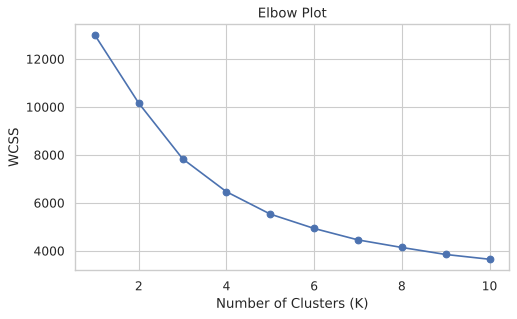

In [111]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), wcss, "o-")
plt.xlabel("Number of Clusters (K)"); plt.ylabel("WCSS"); plt.title("Elbow Plot")
plt.show()

**Q12. K-Means based on the elbow recommendation.**

In [112]:
elbow_k = 3
kmeans_elbow = KMeans(n_clusters=elbow_k, n_init=25, random_state=123).fit(scaled_data)
print("Cluster assignments:", kmeans_elbow.labels_)
display(pd.DataFrame(kmeans_elbow.cluster_centers_, columns=scaled_data.columns, index=range(1, elbow_k + 1)).round(3))
print(pd.Series(kmeans_elbow.labels_).value_counts().sort_index())
print()
print(pd.crosstab(data["mode"], kmeans_elbow.labels_, rownames=["mode"], colnames=["cluster"]))

Cluster assignments: [1 0 1 ... 1 1 1]
   price  catch  pbeach  ppier  pboat  pcharter  cbeach  cpier  cboat  ccharter  income
1 -0.169 -0.389  -0.292 -0.292 -0.241    -0.261  -0.615 -0.569 -0.419    -0.457  -0.049
2  0.433  0.012   0.708  0.708  0.677     0.742   1.269  1.234 -0.120     0.012   0.168
3 -0.193  2.017  -0.229 -0.229 -0.420    -0.479   0.067 -0.091  2.500     2.371  -0.162
0    710
1    337
2    135
Name: count, dtype: int64

cluster    0    1   2
mode                 
beach     83   51   0
boat     263   89  66
charter  245  138  69
pier     119   59   0


### PART B: Hierarchical Clustering

**Q1. Prepare the numeric data.**

In [113]:
hierarchical_data = data.select_dtypes(include="number").drop(columns=["rownames"], errors="ignore").dropna()

**Q2. View the dataset.**

In [114]:
display(hierarchical_data.head())
hierarchical_data.info()

     price   catch   pbeach    ppier    pboat  pcharter  cbeach   cpier   cboat  ccharter     income
0  182.930  0.5391  157.930  157.930  157.930   182.930  0.0678  0.0503  0.2601    0.5391  7083.3317
1   34.534  0.4671   15.114   15.114   10.534    34.534  0.1049  0.0451  0.1574    0.4671  1249.9998
2   24.334  0.2413  161.874  161.874   24.334    59.334  0.5333  0.4522  0.2413    1.0266  3749.9999
3   15.134  0.0789   15.134   15.134   55.930    84.930  0.0678  0.0789  0.1643    0.5391  2083.3332
4   41.514  0.1082  106.930  106.930   41.514    71.014  0.0678  0.0503  0.1082    0.3240  4583.3320
<class 'pandas.DataFrame'>
RangeIndex: 1182 entries, 0 to 1181
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   price     1182 non-null   float64
 1   catch     1182 non-null   float64
 2   pbeach    1182 non-null   float64
 3   ppier     1182 non-null   float64
 4   pboat     1182 non-null   float64
 5   pcharter  1182 non-n

**Q3. Check missing values.**

In [115]:
hierarchical_data.isna().sum()

price       0
catch       0
pbeach      0
ppier       0
pboat       0
pcharter    0
cbeach      0
cpier       0
cboat       0
ccharter    0
income      0


**Q4. Select only numerical attributes.**

In [116]:
hierarchical_data = hierarchical_data.select_dtypes(include="number")
hierarchical_data.head()

     price   catch   pbeach    ppier    pboat  pcharter  cbeach   cpier   cboat  ccharter     income
0  182.930  0.5391  157.930  157.930  157.930   182.930  0.0678  0.0503  0.2601    0.5391  7083.3317
1   34.534  0.4671   15.114   15.114   10.534    34.534  0.1049  0.0451  0.1574    0.4671  1249.9998
2   24.334  0.2413  161.874  161.874   24.334    59.334  0.5333  0.4522  0.2413    1.0266  3749.9999
3   15.134  0.0789   15.134   15.134   55.930    84.930  0.0678  0.0789  0.1643    0.5391  2083.3332
4   41.514  0.1082  106.930  106.930   41.514    71.014  0.0678  0.0503  0.1082    0.3240  4583.3320


**Q5. Standardize the data.**

In [117]:
scaled_hierarchical = scale(hierarchical_data)
scaled_hierarchical.head().round(4)

    price   catch  pbeach   ppier   pboat  pcharter  cbeach   cpier   cboat  ccharter  income
0  2.4308  0.2671  0.5259  0.5259  1.6372    1.5509 -0.9080 -0.6978  0.4237   -0.1278  1.2120
1 -0.3260  0.1387 -0.8521 -0.8521 -0.7131   -0.7844 -0.7135 -0.7302 -0.0659   -0.2298 -1.1573
2 -0.5155 -0.2641  0.5640  0.5640 -0.4931   -0.3941  1.5323  1.8079  0.3341    0.5626 -0.1419
3 -0.6864 -0.5538 -0.8519 -0.8519  0.0107    0.0087 -0.9080 -0.5195 -0.0330   -0.1278 -0.8189
4 -0.1963 -0.5016  0.0338  0.0338 -0.2191   -0.2103 -0.9080 -0.6978 -0.3004   -0.4325  0.1966


**Q6–Q7. Euclidean distance and hierarchical clustering using Ward's method.**

In [118]:
hierarchical_model = linkage(scaled_hierarchical.values, method="ward", metric="euclidean")

**Q8. Dendrogram.**

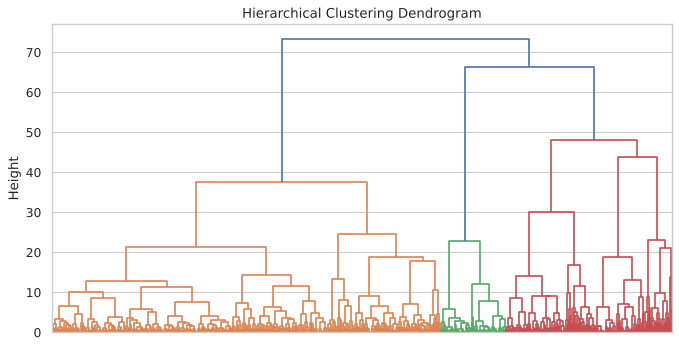

In [119]:
plt.figure(figsize=(10, 5))
dendrogram(hierarchical_model, no_labels=True)
plt.title("Hierarchical Clustering Dendrogram"); plt.ylabel("Height")
plt.show()

**Q9. Divide into 3 clusters and display assignments.**

In [120]:
hierarchical_clusters = fcluster(hierarchical_model, t=3, criterion="maxclust")
hierarchical_clusters

array([3, 1, 3, ..., 3, 3, 3], shape=(1182,), dtype=int32)


**Q10. Number of samples in each cluster.**

In [121]:
pd.Series(hierarchical_clusters).value_counts().sort_index()

1    741
2    125
3    316


## ASSESSMENT IX — Principal Component Analysis

**Q1. Load the dataset and the required libraries.**

In [122]:
from sklearn.decomposition import PCA
data = pd.read_csv(data_path)

**Q2. Number of rows and columns.**

In [123]:
print("Number of rows:", data.shape[0])
print("Number of columns:", data.shape[1])

Number of rows: 1182
Number of columns: 13


**Q3. Extract numeric columns, clean, and normalize into data_scaled.**

In [124]:
numeric_data = data.select_dtypes(include="number").dropna()
numeric_data = numeric_data.loc[:, numeric_data.std(ddof=1) > 0]
data_scaled = scale(numeric_data)
data_scaled.head().round(4)

   rownames   price   catch  pbeach   ppier   pboat  pcharter  cbeach   cpier   cboat  ccharter  income
0   -1.7299  2.4308  0.2671  0.5259  0.5259  1.6372    1.5509 -0.9080 -0.6978  0.4237   -0.1278  1.2120
1   -1.7269 -0.3260  0.1387 -0.8521 -0.8521 -0.7131   -0.7844 -0.7135 -0.7302 -0.0659   -0.2298 -1.1573
2   -1.7240 -0.5155 -0.2641  0.5640  0.5640 -0.4931   -0.3941  1.5323  1.8079  0.3341    0.5626 -0.1419
3   -1.7211 -0.6864 -0.5538 -0.8519 -0.8519  0.0107    0.0087 -0.9080 -0.5195 -0.0330   -0.1278 -0.8189
4   -1.7181 -0.1963 -0.5016  0.0338  0.0338 -0.2191   -0.2103 -0.9080 -0.6978 -0.3004   -0.4325  0.1966


**Q4. PCA on data_scaled with summary.**

In [125]:
pca = PCA().fit(data_scaled)
pc_names = [f"PC{i}" for i in range(1, len(pca.explained_variance_) + 1)]
pca_summary = pd.DataFrame({
    "Standard deviation": np.sqrt(pca.explained_variance_),
    "Proportion of Variance": pca.explained_variance_ratio_,
    "Cumulative Proportion": np.cumsum(pca.explained_variance_ratio_)}, index=pc_names).T
print("Importance of components:")
print(pca_summary.round(5).to_string())

Importance of components:
                            PC1      PC2      PC3      PC4      PC5      PC6      PC7      PC8      PC9     PC10     PC11  PC12
Standard deviation      1.85233  1.73965  1.36136  1.25982  0.93412  0.75556  0.52321  0.42196  0.38616  0.23639  0.04272   0.0
Proportion of Variance  0.28593  0.25220  0.15444  0.13226  0.07271  0.04757  0.02281  0.01484  0.01243  0.00466  0.00015   0.0
Cumulative Proportion   0.28593  0.53812  0.69257  0.82483  0.89754  0.94511  0.96793  0.98276  0.99519  0.99985  1.00000   1.0


**Q5. Scree plot (percentage of variance with data labels, y-axis 0–60).**

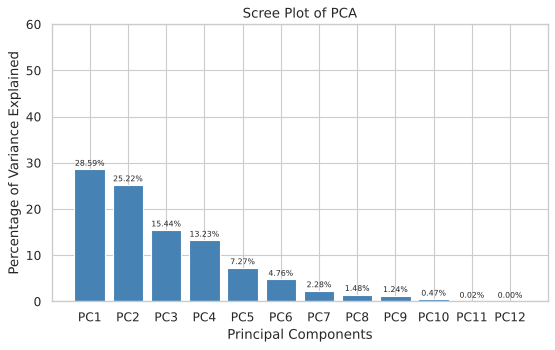

In [126]:
variance = pca.explained_variance_ratio_ * 100
plt.figure(figsize=(8, 4.5))
bars = plt.bar(pc_names, variance, color="steelblue")
for b, v in zip(bars, variance):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.8, f"{v:.2f}%", ha="center", fontsize=7)
plt.ylim(0, 60)
plt.title("Scree Plot of PCA"); plt.xlabel("Principal Components"); plt.ylabel("Percentage of Variance Explained")
plt.show()

**Q6. PCA biplot.**

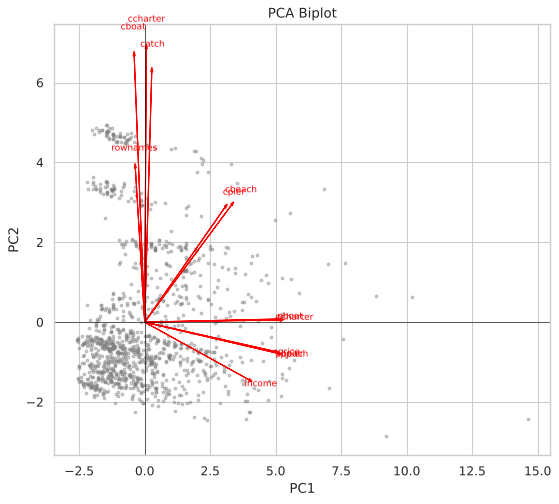

In [127]:
scores = pca.transform(data_scaled)
loadings = pca.components_.T
arrow_scale = np.abs(scores[:, :2]).max() * 0.9
plt.figure(figsize=(8, 7))
plt.scatter(scores[:, 0], scores[:, 1], s=6, alpha=0.4, color="gray")
for i, var in enumerate(data_scaled.columns):
    plt.arrow(0, 0, loadings[i, 0] * arrow_scale, loadings[i, 1] * arrow_scale, color="red", head_width=0.08, length_includes_head=True)
    plt.text(loadings[i, 0] * arrow_scale * 1.08, loadings[i, 1] * arrow_scale * 1.08, var, color="red", ha="center", fontsize=8)
plt.axhline(0, color="black", linewidth=0.5); plt.axvline(0, color="black", linewidth=0.5)
plt.title("PCA Biplot"); plt.xlabel("PC1"); plt.ylabel("PC2")
plt.show()

**Q7. Extract PCA scores into pca_scores and display the first six rows.**

In [128]:
pca_scores = pd.DataFrame(scores, columns=pc_names)
print(pca_scores.head(6).round(4))

      PC1     PC2     PC3     PC4     PC5     PC6     PC7     PC8     PC9    PC10    PC11  PC12
0  2.6352 -0.9303  1.4767 -2.2029 -1.5764  0.2646 -0.1168  0.1757 -0.0197 -0.3798  0.0107  -0.0
1 -2.0616 -0.6929  0.1523 -0.1956 -1.7785  0.0416 -0.0243 -0.2132 -0.3143 -0.1434 -0.0280   0.0
2  0.7157  0.5506 -1.6299  1.6828 -1.5735  1.1629 -0.4681  0.1507 -0.1148  0.1407  0.0060  -0.0
3 -1.5092 -0.9635  0.7881 -0.0446 -1.3069  0.6705 -0.6275 -0.2266 -0.7331 -0.0675  0.0183  -0.0
4 -0.5151 -1.5289 -0.2314 -0.7411 -1.0236  0.6335 -0.2437 -0.1362 -0.4696 -0.1008  0.0228  -0.0
5  1.4096 -0.0826 -1.6756  1.5183 -1.6112  0.7421  0.2292  0.3374  0.1268 -0.2699  0.0407  -0.0


**Q8. Scatter plot of PC1 vs PC2 (blue circular points).**

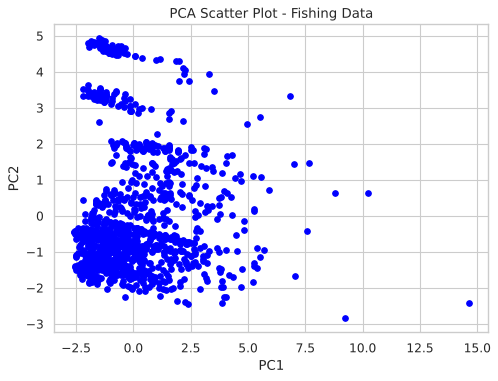

In [129]:
plt.figure(figsize=(7, 5))
plt.scatter(pca_scores["PC1"], pca_scores["PC2"], color="blue", marker="o", s=25)
plt.title("PCA Scatter Plot - Fishing Data")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.show()